## Load libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib as mpl
import matplotlib.pyplot as plt
# import matplotlib as mpl
# from mpl_toolkits.axes_grid1 import make_axes_locatable

import numpy as np
import pynbody as pnb
# import pandas as pd
# pd.set_option('display.max_columns', None)
# import h5py

# import mmappickle
# import klepto

# import periodictable as pt

# import time
import copy

import os
# from pathlib import Path
# from glob import glob
import pprint

import dill

# import astropy.constants as c
# import astropy.units as u
# import astropy.io.fits as pyfits
# # from astropy.table import Table

# from num2tex import num2tex, configure
# configure(exp_format='times', display_singleton=True)

# import oppenheimer21.groups_profiles_all as plot_group_data
# from oppenheimer21.groups_profiles_all import run_plotting_script as opp21_plot
# import oppenheimer21.group_data

from palettable.cartocolors.sequential import DarkMint_7, BurgYl_7, Purp_7, Sunset_7, agGrnYl_7

# plt.rcParams['figure.figsize'] = (15,8)

import pprint

import gc

In [2]:
# from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mp, mu_e, mu, G_no_units, G, R500_OVER_R200, R200_OVER_R500, R2500_OVER_R200, R200_OVER_R2500, R2500_OVER_R500, R500_OVER_R2500
from solar_abundances import info_Asplund09, info_Lodders09, info_Lodders03

# import group_xray_profiles_observations as xobs
# from plot_sim_profiles import plot_property, plot_sims_separate, plot_sims_together, plot_grid
from plot_sim_profiles import plot_grid

import scaling_relation_functions as scale

from astro_constants import Rxxx_conversions #Rxxx_values, 

num2tex configure options:
 - help_text: boolean whether this help text is displayed when configure() is called
 - exp_format: string format specification for how the power of 10 is displayed in scientific format.
     - also accepts specifiers 'times', which is converted to '\times 10^{}', 'cdot': '\cdot 10^{}', and 'parentheses': '(10^{})'
 - display_singleton: boolean on whether the "1 \times" is printed in "1 \times 10^{p}"
          


In [3]:
from group_xray_profiles_observations import obs_werner06, obs_sarkar22, obs_mernier17

In [4]:
# obs_werner06['individual']['M87']['M500']#.keys()

In [5]:
# obs_sarkar22['M500']['simbac_full_scaling_renier']#.keys()

In [6]:
pprint.pprint(obs_mernier17['group_properties']['M500'])#.keys()#['simbac_full_scaling_renier']#.keys()

{'ACCEPT_T/Sun2009_scaling': {'2A0335': SimArray(1.74456746e+14, 'Msol'),
                              'A133': SimArray(2.66291155e+14, 'Msol'),
                              'A1795': SimArray(9.2108625e+14, 'Msol'),
                              'A1991': SimArray(4.98425085e+14, 'Msol'),
                              'A2029': SimArray(8.39762423e+14, 'Msol'),
                              'A2052': SimArray(1.84690039e+14, 'Msol'),
                              'A2199': SimArray(3.19810621e+14, 'Msol'),
                              'A2597': SimArray(2.50892089e+14, 'Msol'),
                              'A262': SimArray(1.09578325e+14, 'Msol'),
                              'A2626': SimArray(1.76484663e+14, 'Msol'),
                              'A3112': SimArray(3.38075273e+14, 'Msol'),
                              'A3526': SimArray(2.9692945e+14, 'Msol'),
                              'A3581': SimArray(1.02945777e+14, 'Msol'),
                              'A4038': SimArray(2.1898

In [7]:
len(obs_mernier17['group_properties']['M500']['simbac_full_scaling_renier'])#.keys()#['simbac_full_scaling_renier']#.keys()

44

In [8]:
# obs_mernier17['individual']['M500']['simbac_full_scaling_renier']#.keys()

In [9]:
# from group_xray_profiles_observations_plotting_functions import include_in_bin

In [10]:
# include_in_bin(pnb.array.SimArray(10**13.6,units='Msol'), 
#                pnb.array.SimArray(10**13,units='Msol'), 
#                pnb.array.SimArray(10**13.5,units='Msol'), 
#                frac=0.25, transform_func=lambda x:np.log10(x))

In [11]:
# 'hello'.split(',')

## Global Definitions for all plots

In [12]:
# COLOR_LIST = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
COLOR_LIST = [DarkMint_7.hex_colors[1:], BurgYl_7.hex_colors[1:], Purp_7.hex_colors[1:],
              Sunset_7.hex_colors[1:], agGrnYl_7.hex_colors[1:],
              ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00', 'darkgreen', 'black', 'pink'],
              ["#3a405a","#7483a3","#aec5eb","#bdc0d9","#ccbac7","#dbb5b5","#e9afa3","#a98074","#685044"]]

# FONTSIZE=22
# plt.rc('font', size=FONTSIZE)          # controls default text sizes
# plt.rc('axes', titlesize=FONTSIZE+4)     # fontsize of the axes title
# plt.rc('axes', labelsize=FONTSIZE+4)    # fontsize of the x and y labels
# plt.rc('xtick', labelsize=FONTSIZE-2)    # fontsize of the tick labels
# plt.rc('ytick', labelsize=FONTSIZE-2)    # fontsize of the tick labels
# plt.rc('legend', fontsize=FONTSIZE)    # legend fontsize
# plt.rc('figure', titlesize=FONTSIZE+2)  # fontsize of the figure title
# #plt.rc('text', fontsize=FONTSIZE)  # fontsize of the figure title
# plt.rc('lines', linewidth=2.5)

## Load saved profiles

In [13]:
profiles_base_dir = '/scratch/b/babul/aspadawe/analysis/simba'

# profiles_save_dirs = ['simba', 'simba-c', 'simba-c', 'simba-c']#, 'simba-c', 'simba-c']#, 'simba-c']
# profiles_save_dirs = ['simba-c/new']
# profiles_save_dirs = ['simba/old', 'simba/old', 'simba/new']
# profiles_save_dirs = ['simba/new', 'simba-c/new', 'simba-c/new']
# profiles_save_dirs = ['simba-c/new', 'simba-c/new']
# profiles_save_dirs = ['simba/final', 'simba/final', 'simba-c/final', 'simba-c/final']
profiles_save_dirs = ['simba/final', 'simba-c/final']
# profiles_save_dirs = ['simba/final', 'simba/final', 'simba-c/final', 'simba-c/final']
# profiles_save_dirs = ['simba/final', 'simba-c/final', 'simba/final', 'simba-c/final', 'simba/final', 'simba-c/final']
# profiles_save_dirs = ['simba/final', 'simba-c/final', 
#                       'simba/final', 'simba-c/final']
# profiles_save_dirs = ['simba/final', 'simba/final',
#                       'simba-c/final', 'simba-c/final']
# profiles_save_dirs = ['simba/final', 'simba/final', 
#                       'simba/final', 'simba/final', 
#                       'simba/final', 'simba/final', 
#                       'simba/final', 'simba/final']
# profiles_save_dirs = ['simba-c/final', 'simba-c/final', 
#                       'simba-c/final', 'simba-c/final', 
#                       'simba-c/final', 'simba-c/final', 
#                       'simba-c/final', 'simba-c/final']
# profiles_save_dirs = ['simba/final', 'simba/final', 
#                       'simba/final', 'simba/final', 
#                       'simba-c/final', 'simba-c/final',
#                       'simba-c/final', 'simba-c/final']
# profiles_save_dirs = ['simba-c/new']
# profiles_save_dirs = ['simba/old', 'simba-c/old']

# profiles_snapshots = ['snapshot_151', 'snapshot_151', 'snapshot_151', 'snapshot_151', 'snapshot_151', 'snapshot_151' , 'snapshot_151', 'snapshot_151']
profiles_snapshots = ['snapshot_151_z0.000', 'snapshot_151_z0.000', 'snapshot_151_z0.000', 'snapshot_151_z0.000',
                      'snapshot_151_z0.000', 'snapshot_151_z0.000' , 'snapshot_151_z0.000', 'snapshot_151_z0.000']
# profiles_snapshots = ['snapshot_151_z0.000', 'snapshot_125_z0.490', 'snapshot_105_z0.993', 'snapshot_078_z2.025',
#                       'snapshot_151_z0.000', 'snapshot_125_z0.490' , 'snapshot_105_z0.993', 'snapshot_078_z2.025']

profiles_save_names = [
#     'Simba_N512L50_igrm_3d_profiles_Nlgal_3_windsremoved_physical_units_intermediatebins_og_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_all_no_classification', # good
#     'Simba_N512L50_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_physical_units_intermediatebins_og_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_all_no_classification', # good
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_metallicity_no_log_no_classification', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_all_no_classification', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_metallicity_no_log_no_classification', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_thermo_no_classification', # GOOD
#     'Simba-C_Kobayashi_Dust_N512L50_igrm_3d_profiles_Nlgal_3_windsremoved_physical_units_intermediatebins_og_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_all_no_classification', # GOOD
#     'Simba-C_Kobayashi_Dust_N512L50_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_physical_units_intermediatebins_og_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_all_no_classification', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_metallicity_no_log_no_classification', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_all_no_classification', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_metallicity_no_log_no_classification', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3_thermo_no_classification', # GOOD
    
    
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-all_props_no_classifications-v0', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v0', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-all_props_no_classifications-v0', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v0', # GOOD
    
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-all_props_no_classifications-v0', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-all_props_no_classifications-v0', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-all_props_no_classifications-v0', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-all_props_no_classifications-v0', # GOOD
    
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v0', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v0', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v0', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v0', # GOOD
    
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-metal_props_no_log_no_classifications-v0', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-metal_props_no_log_no_classifications-v0', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-metal_props_no_log_no_classifications-v0', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-metal_props_no_log_no_classifications-v0', # GOOD
    
    
    
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-all_props_no_classifications-v1', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-all_props_no_classifications-v1', # GOOD ***
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-all_props_no_classifications-v2', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-all_props_no_classifications-v2', # GOOD ***
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v1', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-all_props_no_classifications-v1', # GOOD ***
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v2', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-all_props_no_classifications-v2', # GOOD ***
    
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-all_props_no_classifications-v1', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-all_props_no_classifications-v2', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-all_props_no_classifications-v1', # GOOD
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-all_props_no_classifications-v2', # GOOD
    
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v1', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v2', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v1', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-metal_props_no_log_no_classifications-v1', # GOOD ***
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v2', # GOOD!!
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-metal_props_no_log_no_classifications-v2', # GOOD ***
    
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-metal_props_no_log_no_classifications-v1', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-metal_props_no_log_no_classifications-v2', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-metal_props_no_log_no_classifications-v1', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-metal_props_no_log_no_classifications-v2', # GOOD
    
    
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-all_props_no_classifications-v1', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-all_props_no_classifications-v2', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v1', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v2', # GOOD
    
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-all_props_no_classifications-v1', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-all_props_no_classifications-v2', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-all_props_no_classifications-v1', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-all_props_no_classifications-v2', # GOOD
    
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v1', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v2', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v1', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v2', # GOOD!!
    
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-metal_props_no_log_no_classifications-v1', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_with_errors-metal_props_no_log_no_classifications-v2', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-metal_props_no_log_no_classifications-v1', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_with_errors-metal_props_no_log_no_classifications-v2', # GOOD
    
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v3-min_part_64', # GOOD!!!!!!
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v3-min_part_32', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v3-min_part_16', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v3-min_part_1', # GOOD
    
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v3-min_part_64', # GOOD!!!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v3-min_part_32', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v3-min_part_16', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications-v3-min_part_1', # GOOD
    
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v3-min_part_64', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v3-min_part_32', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v3-min_part_16', # GOOD
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v3-min_part_1', # GOOD
    
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v3-min_part_64', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v3-min_part_32', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v3-min_part_16', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-metal_props_no_log_no_classifications-v3-min_part_1', # GOOD
    
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD!!!!
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-mean_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD
    
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-physical-xscale-median_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-physical-xscale-median_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD!!!!
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-physical-xscale-mean_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-physical-xscale-mean_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD
    
    
    
    ## 2d R/R500 profiles
#     'Simba_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications',#-v3-min_part_64', # GOOD!!!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_cylindrical_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props_no_log_no_classifications',#-v3-min_part_64', # GOOD!!!!!!
    
    'Simba_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props',#-v3-min_part_64', # GOOD!!!!!!
#     'Simba_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-full_annulus_res',
#     'Simba_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-quartiles',#-v3-min_part_64', # GOOD!!!!!!
    
#     'Simba_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props',#-v3-min_part_64', # GOOD!!!!!!
    
    'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props',#-v3-min_part_64', # GOOD!!!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-full_annulus_res',
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-quartiles',#-v3-min_part_64', # GOOD!!!!!!
    
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props',#-v3-min_part_64', # GOOD!!!!!!
    
    ## 2d R/R500 profiles with CC/NCC classifications (N1024L100)
#     'Simba_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v3-min_part_64', # GOOD!!!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v3-min_part_64', # GOOD!!!!!!
    
    ## 2d R/R500 profiles with CC/NCC classifications (N1024L100), thermo props
#     'Simba_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-thermo_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-thermo_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## 2d R/R500 profiles with CC/NCC classifications (N1024L100), metal props
#     'Simba_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## 2d R/R500 profiles with CC/NCC classifications (N512L50)
#     'Simba_NoFB_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
    ## 2d R profiles (N512L50)
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_Physical_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_Physical_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props', # GOOD!!!!!!
    
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_Physical_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-full_annulus_res', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_Physical_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-full_annulus_res', # GOOD!!!!!!
    
    
    
    ## 3d R/R500 profiles (N1024L100)
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD!!!!
    
#     'Simba_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props',#-v3-min_part_64', # GOOD!!!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props',#-v3-min_part_64', # GOOD!!!!!!
    
#     'Simba_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-with_median',#-v3-min_part_64', # GOOD!!!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-with_median',#-v3-min_part_64', # GOOD!!!!!!
    
    ## 3d R/R500 profiles with CC/NCC classifications (N1024L100), thermo props
#     'Simba_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-thermo_props-CC_classifications-v2', # GOOD!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-thermo_props-CC_classifications-v2', # GOOD!!!!
    
    ## 3d R/R500 profiles with CC/NCC classifications (N1024L100), metal props
#     'Simba_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props-CC_classifications-v2', # GOOD!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-metal_props-CC_classifications-v2', # GOOD!!!!
    
    ## 3d R/R500 profiles with CC/NCC classifications (N512L50)
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_CC_classifications-v3-min_part_64', # GOOD!!!!!!
#     'Kobayashi_Dust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props_CC_classifications-v3-min_part_64', # GOOD!!!!!!
    
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
    ## 3d R profiles
#     'Simba_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-physical-xscale-median_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD!!!!
#     'Simba-C_Kobayashi_Dust_N1024L100_igrm_3d_profiles_Nlgal_3_windsremoved_r500_intermediatebins_good_temp_cut=5e5 K_nh_cut=0.13 cm**-3-physical-xscale-median_no_errors-all_props_no_classifications-v3-min_part_64', # GOOD!!!!
    
    ## 3d R profiles (N512L50)
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_Physical_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_Physical_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props', # GOOD!!!!!!
    
    
    ## Redshift evolution ##################
    
    ## 2d
    
    ## Simba NoFB 2d N512L50
#     'Simba_NoFB_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
    ## Simba NoAGN 2d N512L50
#     'Simba_NoAGN_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
    ## Simba NoJet 2d N512L50
#     'Simba_NoJet_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
    ## Simba 2d N512L50
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## Simba-C 2d N512L50
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## Simba-C NoDust 2d N512L50
#     'Kobayashi_NoDust_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
    
    
    ## 3d
    
    ## Simba NoFB 3d N512L50
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoFB_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## Simba NoAGN 3d N512L50
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoAGN_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## Simba NoJet 3d N512L50
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_NoJet_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## Simba 3d N512L50
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Simba_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## Simba-C 3d N512L50
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
    
    ## Simba-C NoDust 3d N512L50
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications', # GOOD!!!!!!
    
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
#     'Kobayashi_NoDust_N512L50_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 K_nh_cut=0.13 cm**-3-median_no_errors-all_props-CC_classifications-v2', # GOOD!!!!!!
                       ]

# profile_codes = ['Simba (No FB)', 'Simba (No AGN)', 'Simba (No Jet)', 'Simba', 'Simba-C']
# profile_codes = ['Simba (No FB)', 'Simba (No AGN)', 'Simba (No Jet)']
# profile_codes = ['Simba', 'Simba-C']
# profile_codes = ['Simba (N512L50)', 'Simba (N1024L100)', 'Simba-C (N512L50)', 'Simba-C (N1024L100)']
# profile_codes = ['Simba (N512L50)', 'Simba-C (N512L50)', 'Simba (N1024L100)', 'Simba-C (N1024L100)']
# profile_codes = ['Simba (N512L50)', 'Simba (N1024L100)', 'Simba-C (N512L50)', 'Simba-C (N1024L100)']
# profile_codes = [r'Simba-C (N256L25) Cylindrical - Height=$6R_{500}$', 'Simba-C (N256L25) Cylindrical = Height=$3R_{500}$']
# profile_codes = [r'Simba (N512L50) Cylindrical - Height=$6R_{500}$', r'Simba (N512L50) Cylindrical - Height=$3R_{500}$', 
#                  r'Simba-C (N512L50) Cylindrical - Height=$6R_{500}$', r'Simba-C (N512L50) Cylindrical - Height=$3R_{500}$']
# profile_codes = ['Simba (N512L50)', 'Simba-C (N512L50)']
# profile_codes = ['Simba 3D Sphere (N512L50)', 'Simba 2D Sphere (N512L50)', 'Simba 2D Cylinder (N512L50)', 
#                  'Simba-C 3D Sphere (N512L50)', 'Simba-C 2D Sphere (N512L50)', 'Simba-C 2D Cylinder (N512L50)',]
profile_codes = ['Simba', 'Simba-C']
# profile_codes = ['Simba (Quartiles)', 'Simba-C (Quartiles)']
# profile_codes = [r'Simba (1$\sigma$)', 'Simba (Quartiles)', r'Simba-C (1$\sigma$)', 'Simba-C (Quartiles)']
# profile_codes = ['Simba (N1024L100)', 'Simba-C (N1024L100)']
# profile_codes = ['Simba (Spherical Res)', 'Simba (Projected Res)',
#                  'Simba-C (Spherical Res)', 'Simba-C (Projected Res)']
# profile_codes = ['Simba 2D', 'Simba-C 2D', 
#                  'Simba 3D', 'Simba-C 3D',]
# profile_codes = ['Simba 2D', 'Simba 3D', 
#                  'Simba-C 2D', 'Simba-C 3D',]
# profile_codes = ['Simba 2D (N512L50)', 'Simba-C 2D (N512L50)', 
#                  'Simba 2D (N512L50; Projected Res)', 'Simba-C 2D (N512L50; Projected Res)',
#                  'Simba 3D (N512L50)', 'Simba-C 3D (N512L50)',]
# profile_codes = ['Simba (N1024L100): Median', 'Simba-C (N1024L100): Median',
#                  'Simba (N1024L100): Mean', 'Simba-C (N1024L100): Mean',]
# profile_codes = ['Simba 3D (N1024L100)', 'Simba 2D (N1024L100)', 
#                  'Simba-C 3D (N1024L100)', 'Simba-C 2D (N1024L100)',]
# profile_codes = ['Simba 3D (N1024L100): Mean V1', 'Simba 3D (N1024L100): Mean V2', 
#                  'Simba 3D (N1024L100): Median V1', 'Simba 3D (N1024L100): Median V2',]
# profile_codes = ['Simba 2D (N1024L100): Mean V1', 'Simba 2D (N1024L100): Mean V2', 
#                  'Simba 2D (N1024L100): Median V1', 'Simba 2D (N1024L100): Median V2',]
# profile_codes = ['Simba 3D (N1024L100): Mean V0', 'Simba 3D (N1024L100): Median V0', 
#                  'Simba-C 3D (N1024L100): Mean V0', 'Simba-C 3D (N1024L100): Median V0',]
# profile_codes = ['Simba 2D (N1024L100): Mean V0', 'Simba 2D (N1024L100): Median V0', 
#                  'Simba-C 2D (N1024L100): Mean V0', 'Simba-C 2D (N1024L100): Median V0',]
# profile_codes = ['Simba 2D (N1024L100): Mean V1', 'Simba 2D (N1024L100): Median V1', 
#                  'Simba-C 2D (N1024L100): Mean V1', 'Simba-C 2D (N1024L100): Median V1',]
# profile_codes = ['Simba 3D (N1024L100): Mean V1', 'Simba 3D (N1024L100): Median V1', 
#                  'Simba-C 3D (N1024L100): Mean V1', 'Simba-C 3D (N1024L100): Median V1',]
# profile_codes = ['Simba 3D (N1024L100): Mean V0', 'Simba 3D (N1024L100): Median V0', 
#                  'Simba 3D (N1024L100): Mean V1', 'Simba 3D (N1024L100): Median V1',
#                  'Simba 3D (N1024L100): Mean V2', 'Simba 3D (N1024L100): Median V2',]
# profile_codes = ['Simba-C 3D (N1024L100): Mean V0', 'Simba-C 3D (N1024L100): Median V0', 
#                  'Simba-C 3D (N1024L100): Mean V1', 'Simba-C 3D (N1024L100): Median V1',
#                  'Simba-C 3D (N1024L100): Mean V2', 'Simba-C 3D (N1024L100): Median V2',]
# profile_codes = ['Simba 2D (N1024L100): Mean V0', 'Simba 2D (N1024L100): Median V0', 
#                  'Simba 2D (N1024L100): Mean V1', 'Simba 2D (N1024L100): Median V1',
#                  'Simba 2D (N1024L100): Mean V2', 'Simba 2D (N1024L100): Median V2',]
# profile_codes = ['Simba-C 2D (N1024L100): Mean V0', 'Simba-C 2D (N1024L100): Median V0', 
#                  'Simba-C 2D (N1024L100): Mean V1', 'Simba-C 2D (N1024L100): Median V1',
#                  'Simba-C 2D (N1024L100): Mean V2', 'Simba-C 2D (N1024L100): Median V2',]
# profile_codes = ['Simba 3D (N1024L100): Median no error V0', 'Simba 3D (N1024L100): Median with error V0', 
#                  'Simba 3D (N1024L100): Median no error V1', 'Simba 3D (N1024L100): Median with error V1',
#                  'Simba 3D (N1024L100): Median no error V2', 'Simba 3D (N1024L100): Median with error V2',]
# profile_codes = ['Simba 2D (N1024L100): Median no error V0', 'Simba 2D (N1024L100): Median with error V0', 
#                  'Simba 2D (N1024L100): Median no error V1', 'Simba 2D (N1024L100): Median with error V1',
#                  'Simba 2D (N1024L100): Median no error V2', 'Simba 2D (N1024L100): Median with error V2',]
# profile_codes = ['Simba 2D (N1024L100): V3/Min 64', 'Simba 2D (N1024L100): V3/Min 32', 
#                  'Simba 2D (N1024L100): V3/Min 16', 'Simba 2D (N1024L100): V3/Min 1', 
#                  'Simba-C 2D (N1024L100): V3/Min 64', 'Simba-C 2D (N1024L100): V3/Min 32', 
#                  'Simba-C 2D (N1024L100): V3/Min 16', 'Simba-C 2D (N1024L100): V3/Min 1', ]
# profile_codes = ['Simba 3D (N512L50)', 'Simba 2D (N512L50)', 
#                  'Simba-C 3D (N512L50)', 'Simba-C 2D (N512L50)',]
# profile_codes = ['Simba 3D (N1024L100)', 'Simba-C 3D (N1024L100)',]
# profile_codes = ['Simba 3D (N512L500)', 'Simba-C 3D (N512L500)',]
# profile_codes = ['Simba 2D (N1024L100)', 'Simba-C 2D (N1024L100)',]
# profile_codes = ['Simba 2D (N512L50)', 'Simba-C 2D (N512L50)',]
# profile_codes = ['Simba NoFB 2D (N512L50)', 'Simba NoAGN 2D (N512L50)', 'Simba NoJet 2D (N512L50)', 
#                  'Simba 2D (N512L50)', 'Simba-C 2D (N512L50)', 'Simba-C NoDust 2D (N512L50)']
# profile_codes = ['Simba NoFB 3D (N512L50)', 'Simba NoAGN 3D (N512L50)', 'Simba NoJet 3D (N512L50)', 
#                  'Simba 3D (N512L50)', 'Simba-C 3D (N512L50)', 'Simba-C NoDust 3D (N512L50)']
# profile_codes = ['Simba 2D (N512L50): z=0', 'Simba 2D (N512L50): z=0.5', 'Simba 2D (N512L50): z=1', 'Simba 2D (N512L50): z=2', 
#                  'Simba-C 2D (N512L50): z=0', 'Simba-C 2D (N512L50): z=0.5', 'Simba-C 2D (N512L50): z=1', 'Simba-C 2D (N512L50): z=2', ]
# profile_codes = ['Simba 3D (N512L50): z=0', 'Simba 3D (N512L50): z=0.5', 'Simba 3D (N512L50): z=1', 'Simba 3D (N512L50): z=2', 
#                  'Simba-C 3D (N512L50): z=0', 'Simba-C 3D (N512L50): z=0.5', 'Simba-C 3D (N512L50): z=1', 'Simba-C 3D (N512L50): z=2']
# profile_codes = ['Simba NoFB 3D (N512L50): z=0', 'Simba NoFB 3D (N512L50): z=0.5', 'Simba NoFB 3D (N512L50): z=1', 'Simba NoFB 3D (N512L50): z=2']
# profile_codes = ['Simba NoAGN 3D (N512L50): z=0', 'Simba NoAGN 3D (N512L50): z=0.5', 'Simba NoAGN 3D (N512L50): z=1', 'Simba NoAGN 3D (N512L50): z=2']
# profile_codes = ['Simba NoJet 3D (N512L50): z=0', 'Simba NoJet 3D (N512L50): z=0.5', 'Simba NoJet 3D (N512L50): z=1', 'Simba NoJet 3D (N512L50): z=2']
# profile_codes = ['Simba 3D (N512L50): z=0', 'Simba 3D (N512L50): z=0.5', 'Simba 3D (N512L50): z=1', 'Simba 3D (N512L50): z=2']
# profile_codes = ['Simba-C 3D (N512L50): z=0', 'Simba-C 3D (N512L50): z=0.5', 'Simba-C 3D (N512L50): z=1', 'Simba-C 3D (N512L50): z=2']
# profile_codes = ['Simba-C NoDust 3D (N512L50): z=0', 'Simba-C NoDust 3D (N512L50): z=0.5', 'Simba-C NoDust 3D (N512L50): z=1', 'Simba-C NoDust 3D (N512L50): z=2']
# profile_codes = ['Simba-C (N256L25)']
# profile_codes = ['Simba Old (N512L50)', 'Simba Old (N1024L100)', 'Simba New (N512L50)']
# profile_codes = ['Simba (N512L50)', 'Simba-C No Dust (N512L50)', 'Simba-C Dust (N512L50)']
# profile_codes = ['Simba (N512L50)', 'Simba-C Dust (N512L50)']
# profile_codes = [r'Simba-C (N512L50): $N_{l,gal} \geq 3$', r'Simba-C (N512L50): $N_{l,gal} \geq 0$']
# profile_codes = ['Simba (N512L50)', 'Simba-C (N512L50)']
# profile_codes = ['Simba-C (N512L50)']
# profile_codes = ['Simba (N1024L100)', 'Simba-C (N1024L100)']
# profile_codes = ['Simba (T>1e5 K)', 'Simba (T>5e5 K)', 'Simba (T>1e6 K)', 'Simba (T>5e6 K)']

profile_code_labels = ['sim_simba', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simba', 'sim_simbac', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simbac', 'sim_simba', 'sim_simbac', 'sim_simba', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simbac', 
#                        'sim_simba', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simba', 'sim_simbac', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simba',
#                        'sim_simba', 'sim_simba', 
#                        'sim_simba', 'sim_simba', 
#                        'sim_simba', 'sim_simba']
# profile_code_labels = ['sim_simbac', 'sim_simbac',
#                        'sim_simbac', 'sim_simbac', 
#                        'sim_simbac', 'sim_simbac', 
#                        'sim_simbac', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simba',
#                        'sim_simba', 'sim_simba', 
#                        'sim_simbac', 'sim_simbac', 
#                        'sim_simbac', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simba',
#                        'sim_simba', 'sim_simba']
# profile_code_labels = ['sim_simbac', 'sim_simbac',
#                        'sim_simbac', 'sim_simbac']
# profile_code_labels = ['sim_simbac']
# profile_code_labels = ['sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simbac', 'sim_simbac']
# profile_code_labels = ['sim_simba', 'sim_simba']

profiles_xaxis = 'bin_centres'
# profiles_xaxis = 'bin_centres_r500'
# profiles_xaxis = 'bin_centres_r500_Lx_0.5-10.0keV_weighted'
# profiles_xaxis = 'log_bin_centres_r500'
# profiles_xaxis = 'logged_linear_bin_centres_r500'
# profiles_xaxis = 'linearized_log_bin_centres_r500'

profiles_xaxis_bins = 'bins'
# profiles_xaxis_bins = 'rbins_r500'
# profiles_xaxis_bins = 'rbins_r500_Lx_0.5-10.0keV_weighted'
# profiles_xaxis_bins = 'log_rbins_r500'

profiles_xunits = 'R500'
# profiles_xunits = 'Physical'

profiles_xaxis_label = r'$R\,/\,R_{500}$'
# profiles_xaxis_label = r'$R\,[kpc]$'
# profiles_xaxis_label = r'$\log(R\,/\,R_{500})$'
# profiles_yaxis = 'linear'

# profiles_binning = 'Tspec_corr'
profiles_binning = 'M500'
# profiles_binning = 'Unbinned'

profiles_binning_name = profiles_binning + '_bins'
# profiles_binning_name = profiles_binning + '_split'
# profiles_binning_name = 'Unbinned'

use_dill = True

x_is_log = False
# y_is_log = False
# plot_x_log = True
# plot_y_log = True

# xray_bands = ['0.5-1.8keV', '0.5-2.0keV', '0.1-2.4keV', '0.5-7.0keV', '0.5-10.0keV']
# xray_bands = ['0.5-10.0keV_total', '0.5-10.0keV_cont']
xray_bands = ['0.5-10.0keV_total']

In [14]:
# profiles_info.clear()
# del profiles_info
# gc.collect()

In [15]:
# resolution_limit = 64.  # minimum number of particles to consider "resolved", and reduce Poisson noise down to at most 12.5% (for 64)

profiles_info = {}


for dir_, snap_, name_, code_, label_ in zip(profiles_save_dirs, profiles_snapshots, profiles_save_names, profile_codes, profile_code_labels):
    
    print(code_)
    
    if use_dill:
        profiles_file = os.path.join(profiles_base_dir, dir_, snap_ + '_' + name_ + '_binned_extended' + '.pkl')
        profiles_stats_file = os.path.join(profiles_base_dir, dir_, snap_ + '_' + name_ + '_binned_stats' + '.pkl')
        parameters_file = os.path.join(profiles_base_dir, dir_, snap_ + '_' + name_ + '_parameters' + '.pkl')
        
        with open(profiles_file, 'rb') as f:
            profiles = dill.load(f)        
        with open(profiles_stats_file, 'rb') as f:
            profiles_stats = dill.load(f)
        with open(parameters_file, 'rb') as f:
            parameters = dill.load(f)
            
    else:
        profiles_file = os.path.join(profiles_base_dir, dir_, snap_ + '_' + name_ + '_binned_extended' + '.npy')
        profiles_stats_file = os.path.join(profiles_base_dir, dir_, snap_ + '_' + name_ + '_binned_stats' + '.npy')
        parameters_file = os.path.join(profiles_base_dir, dir_, snap_ + '_' + name_ + '_parameters' + '.npy')
        
        profiles = np.load(profiles_file, allow_pickle=True).item()
        profiles_stats = np.load(profiles_stats_file, allow_pickle=True).item()
        parameters = np.load(parameters_file, allow_pickle=True).item()
    
#     profiles = np.load(profiles_file, allow_pickle=True, mmap_mode='r').item()
#     profiles_stats = np.load(profiles_stats_file, allow_pickle=True, mmap_mode='r').item()
    
#     profiles = mmappickle.mmapdict(profiles_file, readonly=True)#.item()
#     profiles_stats = mmappickle.mmapdict(profiles_stats_file, readonly=True)#.item()

# #     profiles = klepto.archives.dict_archive(name=profiles_file, dict={}, cached=False)
# #     profiles = klepto.archives.dir_archive(name=profiles_file, dict={}, cached=True)
#     profiles = klepto.archives.file_archive(profiles_file, {}, cached=False, serialized=True)
#     profiles.load()
# #     profiles_stats = klepto.archives.dict_archive(name=profiles_stats_file, dict={}, cached=False)
# #     profiles_stats = klepto.archives.dir_archive(name=profiles_stats_file, dict={}, cached=True)
#     profiles_stats = klepto.archives.file_archive(profiles_stats_file, {}, cached=False, serialized=True)
#     profiles_stats.load()
    
        
        
    print('Parameters:')
    pprint.pprint(parameters)
        
    metals_idx_ = profiles[profiles_binning_name]['metals_idx']
    
    
#     print(profiles[profiles_binning_name]['bin_edges'])
    
    
# #     print(profiles[profiles_binning_name].keys())
# #     first_bin_ = list(profiles[profiles_binning_name].keys())[0]
#     first_bin_ = profiles[profiles_binning_name]['bins'][0]
#     first_classification_ = profiles[profiles_binning_name]['classifications'][0]
# #     print(first_classification_)
    
#     print(profiles[profiles_binning_name][first_bin_].keys())
    
    
    profiles_info[code_] = {
        'parameters':parameters,
        'profiles':profiles[profiles_binning_name],
        'profiles_stats':profiles_stats[profiles_binning_name],
        'metals_idx':metals_idx_,
#         'XAXIS':profiles[profiles_binning_name][0][profiles[profiles_binning_name][0]['id'][0]][profiles_xaxis],  # choose correct axis here
#         'XAXIS':profiles[profiles_binning_name][first_bin_][first_classification_+'_profiles'][profiles[profiles_binning_name][first_bin_][first_classification_+'_id'][0]]['x'][profiles_xaxis],  # choose correct axis here
        'XSCALE':profiles[profiles_binning_name]['xaxis']['all']['scale'],
        'XAXIS':profiles[profiles_binning_name]['xaxis']['all'][profiles_xaxis],
#         'XAXIS_BINS':profiles[profiles_binning_name][0][profiles[profiles_binning_name][0]['id'][0]][profiles_xaxis_bins],  # choose correct axis here
#         'XAXIS_BINS':profiles[profiles_binning_name][first_bin_][first_classification_+'_profiles'][profiles[profiles_binning_name][first_bin_][first_classification_+'_id'][0]]['x'][profiles_xaxis_bins],  # choose correct axis here
        'XAXIS_BINS':profiles[profiles_binning_name]['xaxis']['all'][profiles_xaxis_bins],
        'BIN_EDGES':profiles[profiles_binning_name]['bin_edges'],
        'BIN_NAME':profiles[profiles_binning_name]['bin_printable_name'],
        'LABEL':'#'+label_+'##',#+code_,
        
    }
    
    
    print('Cleaning...')
    del profiles
    del profiles_stats
    gc.collect()


    print("DONE")
    print()

Simba
Parameters:
{'avg_type': 'median',
 'calc_log_props': True,
 'calc_metal_props': True,
 'calc_thermo_props': True,
 'change_xscale': False,
 'classify_halos': False,
 'code': 'Simba',
 'dir': '/scratch/b/babul/aspadawe/analysis/simba/simba/final',
 'include_resolution_cuts': True,
 'min_frac_resolved_halos': 0.16,
 'min_resolved_counts_per_bin': 64,
 'min_resolved_counts_per_halo': 64,
 'min_resolved_counts_per_halo_core': 16,
 'min_resolved_halos': 5,
 'min_total_halos': 0,
 'name': 'Simba_N1024L100_igrm_2d_Cylinder_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 '
         'K_nh_cut=0.13 cm**-3',
 'ndim': 2,
 'new_xscale': 'None',
 'profiles_are_2d_but_res_file_is_3d': True,
 'res_file': 'Simba_N1024L100_igrm_3d_Sphere_profiles_Nlgal_3_windsremoved_xscale_R500_intermediatebins_temp_cut=5e5 '
             'K_nh_cut=0.13 cm**-3',
 'size': 'N1024L100',
 'snap': 'snapshot_151_z0.000',
 'suffix': 'median_no_errors-all_props',
 'three_d_file': 'Simba_N1024L100

In [16]:
rhocrit_1 = profiles_info[list(profiles_info.keys())[0]]['profiles']['cosmo_props']['rho_crit']
fb_1 = profiles_info[list(profiles_info.keys())[0]]['profiles']['cosmo_props']['OmegaB0'] / profiles_info[list(profiles_info.keys())[0]]['profiles']['cosmo_props']['OmegaM0']
fb_rhocrit_1 = profiles_info[list(profiles_info.keys())[0]]['profiles']['cosmo_props']['rho_gas_scaling']
OmegaB0_1 = profiles_info[list(profiles_info.keys())[0]]['profiles']['cosmo_props']['OmegaB0']
OmegaM0_1 = profiles_info[list(profiles_info.keys())[0]]['profiles']['cosmo_props']['OmegaM0']

rhocrit_2 = profiles_info[list(profiles_info.keys())[1]]['profiles']['cosmo_props']['rho_crit']
fb_2 = profiles_info[list(profiles_info.keys())[1]]['profiles']['cosmo_props']['OmegaB0'] / profiles_info[list(profiles_info.keys())[1]]['profiles']['cosmo_props']['OmegaM0']
fb_rhocrit_2 = profiles_info[list(profiles_info.keys())[1]]['profiles']['cosmo_props']['rho_gas_scaling']
OmegaB0_2 = profiles_info[list(profiles_info.keys())[1]]['profiles']['cosmo_props']['OmegaB0']
OmegaM0_2 = profiles_info[list(profiles_info.keys())[1]]['profiles']['cosmo_props']['OmegaM0']

Xprim_simba = 0.7381
Xprim_simbac = 0.7551

Yprim_simba = 0.2485
Yprim_simbac = 0.2449

print(r'Simba: $\rho_{\mathrm{crit}}=$', rhocrit_1, rhocrit_1.units)
print(r'Simba-C: $\rho_{\mathrm{crit}}=$', rhocrit_2, rhocrit_2.units)
print()
print(r'Simba: $\Omega_{B,0}=$', OmegaB0_1)#, fb_1.units)
print(r'Simba-C: $\Omega_{B,0}=$', OmegaB0_2)#, fb_2.units)
print()
print(r'Simba: $\Omega_{M,0}=$', OmegaM0_1)#, fb_1.units)
print(r'Simba-C: $\Omega_{M,0}=$', OmegaM0_2)#, fb_2.units)
print()
print(r'Simba: $f_b = \Omega_{B,0}/\Omega_{M,0}=$', fb_1)#, fb_1.units)
print(r'Simba-C: $f_b = \Omega_{B,0}/\Omega_{M,0}=$', fb_2)#, fb_2.units)
print()
print(r'Simba: $X_{primordial}=$', Xprim_simba)
print(r'Simba-C: $X_{primordial}=$', Xprim_simbac)
print()
print(r'Simba: $Y_{primordial}=$', Yprim_simba)
print(r'Simba-C: $Y_{primordial}=$', Yprim_simbac)

Simba: $\rho_{\mathrm{crit}}=$ 128.32512662583213 Msol kpc**-3
Simba-C: $\rho_{\mathrm{crit}}=$ 128.32512662583213 Msol kpc**-3

Simba: $\Omega_{B,0}=$ 0.0482
Simba-C: $\Omega_{B,0}=$ 0.0482

Simba: $\Omega_{M,0}=$ 0.3
Simba-C: $\Omega_{M,0}=$ 0.3

Simba: $f_b = \Omega_{B,0}/\Omega_{M,0}=$ 0.16066666666666668
Simba-C: $f_b = \Omega_{B,0}/\Omega_{M,0}=$ 0.16066666666666668

Simba: $X_{primordial}=$ 0.7381
Simba-C: $X_{primordial}=$ 0.7551

Simba: $Y_{primordial}=$ 0.2485
Simba-C: $Y_{primordial}=$ 0.2449


In [17]:
# profiles_info['Simba-C (N1024L100)']['profiles_stats'][3]['all_profiles']['avg'].keys()#['median']['Z_Lx_0.5-10.0keV_total_solar_asplund09']#.keys()

In [18]:
# profiles_info['Simba-C 3D (N1024L100): Median V1']['profiles_stats'][3]['all_profiles'].keys()#['median']['Z_Lx_0.5-10.0keV_total_solar_asplund09']#.keys()

In [19]:
# profiles_info['Simba 3D (N1024L100): Mean V2']['profiles_stats'][3]['all_profiles']['median']['Z_Lx_0.5-10.0keV_total_solar_asplund09']#.keys()

In [20]:
# profiles_info['Simba (N512L50)']['BIN_EDGES'][1]

In [21]:
# profiles_info[r'Simba (N512L50)']['profiles'][3]['all_core_profiles'].keys()

In [22]:
# profiles_info[r'Simba (N512L50)']['profiles'][3]['all_core_profiles'][21704]['y']['tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total']

In [23]:
# profiles_info[r'Simba-C (N512L50): $N_{l,gal} \geq 3$']['profiles'][3]['halo_info']['N_lgal']#.keys()

In [24]:
# profiles_info[r'Simba-C (N512L50): $N_{l,gal} \geq 3$']['profiles'][4]['halo_info']['N_lgal']#.keys()

In [25]:
# profiles_info[r'Simba-C (N512L50): $N_{l,gal} \geq 3$']['profiles'][5]['halo_info']['N_lgal']#.keys()

In [26]:
# profiles_info[r'Simba-C (N512L50): $N_{l,gal} \geq 0$']['profiles'][3]['halo_info']['N_lgal']#.keys()

In [27]:
# profiles_info[r'Simba-C (N512L50): $N_{l,gal} \geq 0$']['profiles'][4]['halo_info']['N_lgal']#.keys()

In [28]:
# profiles_info[r'Simba-C (N512L50): $N_{l,gal} \geq 0$']['profiles'][5]['halo_info']['N_lgal']#.keys()

In [29]:
# profiles_info['Simba New (N512L50)']['profiles'][3]['all_profiles'][1]['y'].keys()

In [30]:
# profiles_info['Simba New (N512L50)']['profiles'][3]['all_profiles'][1]['y']['metal_mass_M500'].units

In [31]:
# profiles_info['Simba New (N512L50)']['profiles'][3]['temp_halo_info'].keys()

In [32]:
# profiles_info['Simba New (N512L50)']['profiles'][3]['temp_halo_info']['S']['500ideal']

In [33]:
# profiles_info['Simba (N1024L100)']['profiles'][3]['all_profiles'][1]['x'].keys()

In [34]:
# profiles_info['Simba (N1024L100)']['profiles'][3]['all_profiles'][1]['x']['bin_centres_r500']

In [35]:
# profiles_info['Simba (N1024L100)']['profiles'][3]['all_profiles'][2]['x']['bin_centres_r500_Lx_0.5-10.0keV_weighted']

In [36]:
# len(profiles_info['Simba-C (N1024L100)']['profiles'][0]['all_profiles'][2]['y'].keys())

In [37]:
# len(profiles_info['Simba-C (N1024L100)']['profiles'][0]['TLx_0.5-10.0keV_CC_frac_profiles'][2]['y'].keys())

## Arbitrary Profiles

['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00', 'darkgreen', 'black', 'pink']
row
elements
['Fe']

col
bins
[3, 4, 5]

overlay0
sims
['Simba', 'Simba-C']


{'row': {'type': 'elements', 'grid': ['Fe'], 'length': 1}, 'col': {'type': 'bins', 'grid': [3, 4, 5], 'length': 3}, 'overlay0': {'type': 'sims', 'grid': ['Simba', 'Simba-C'], 'length': 2}, 'nrows': 1, 'ncols': 3}


nrows = 1
ncols = 3
noverlay = [2]

row 0 : elements
row 0 : elements Fe
current_info:
dict_keys(['code', 'info', 'bin_', 'prop', 'classification', 'element', 'element_num', 'element_denom'])
code: Simba
bin_: 3
prop: Z_Lx_0.5-10.0keV_total_solar_asplund09
classification: all
element: Fe
element_num: None
element_denom: None

col 0 : bins
col 0 : bins 3
current_info:
dict_keys(['code', 'info', 'bin_', 'prop', 'classification', 'element', 'element_num', 'element_denom'])
code: Simba
bin_: 3
prop: Z_Lx_0.5-10.0keV_total_solar_asplund09
classification: all
element: Fe
element_num: None
element_denom: None

Not plotti

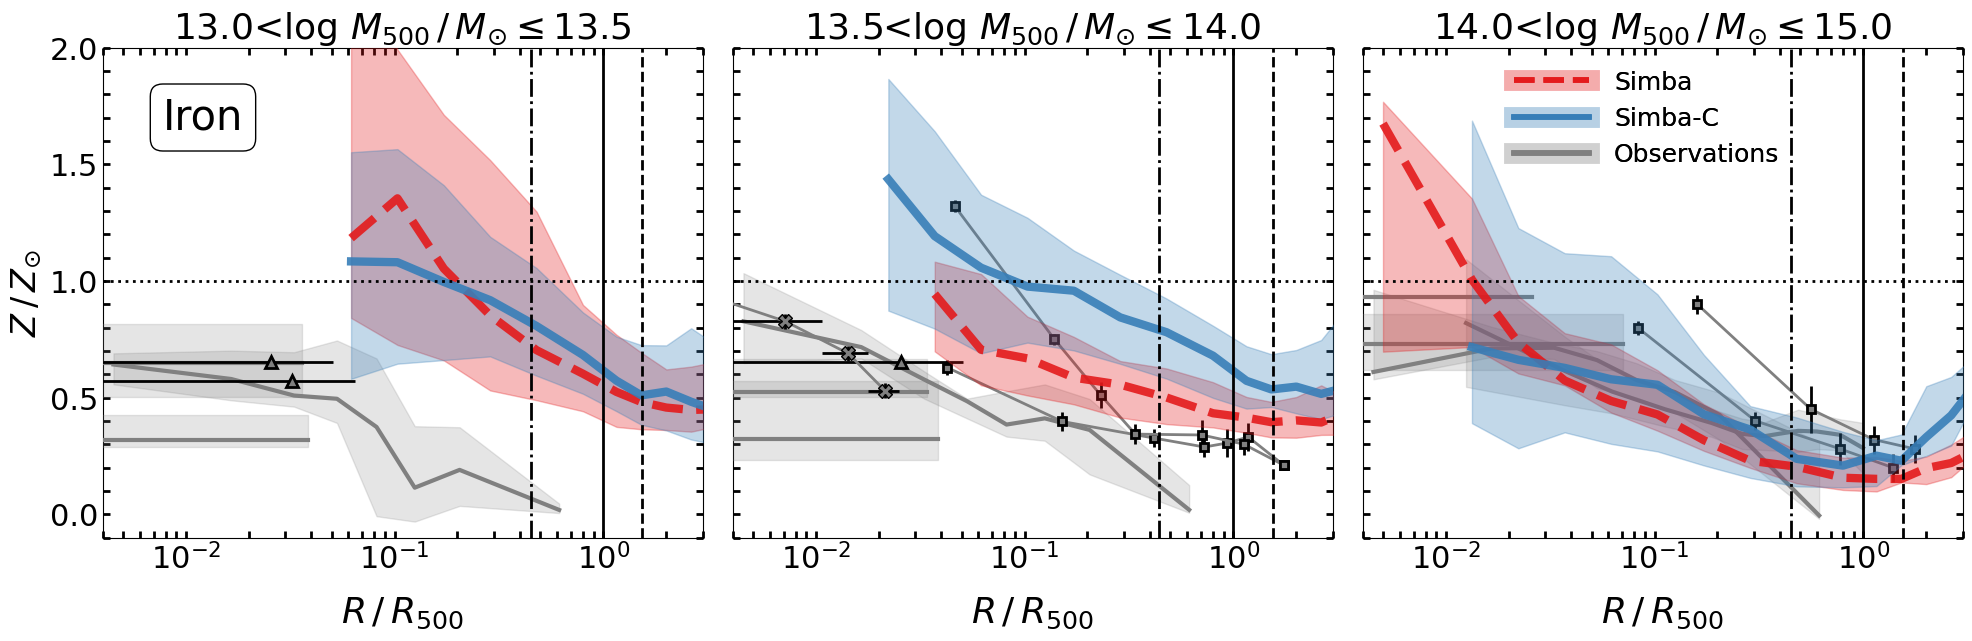

In [ ]:
# Plot a grid of whatever profiles you want

######### Set properties ##########################################################################

type_ = 'regular'
type_ = 'metallicity'
# type_ = 'metallicity ratio'

bin_prop_ = ['M', '500']
# bin_prop_ = ['T', 'spec_corr']
# bins_to_plot_ = [0,1,2,3,4,5,6]
bins_to_plot_ = [3,4,5]
# bins_to_plot_ = [3,4]
# bins_to_plot_ = [0,1]
# bins_to_plot_ = [5,5]
# bins_to_plot_ = [1,2]



# classifications_ = ['Tspec_CC_frac', 'Tspec_NCC_frac']
# classifications_ = ['Tnoweight_CC_frac', 'Tnoweight_NCC_frac']
# classifications_ = ['TLx_0.5-10.0keV_CC_frac', 'TLx_0.5-10.0keV_NCC_frac']
# classifications_ = ['TLx_0.5-10.0keV_CC_sigma', 'TLx_0.5-10.0keV_NCC_sigma']
# classifications_ = ['CC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin', 
#                     'Weak_CC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin',
#                     'NCC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin']
# classifications_ = ['CC_temp_frac_T_Lx_0.5-10.0keV_total', 'NCC_temp_frac_T_Lx_0.5-10.0keV_total']
classifications_ = ['all']
# classifications_ = ['CC_temp_frac_T_spec', 'NCC_temp_frac_T_spec']
# classifications_ = ['CC_temp_frac_T_Lx_0.5-10.0keV_total', 'NCC_temp_frac_T_Lx_0.5-10.0keV_total']
# classifications_ = ['CC_temp_frac_T_mass', 'NCC_temp_frac_T_mass']
# classifications_ = ['CC_temp_sigma_T_spec', 'NCC_temp_sigma_T_spec']
# classifications_ = ['CC_temp_sigma_T_Lx_0.5-10.0keV_total', 'NCC_temp_sigma_T_Lx_0.5-10.0keV_total']
# classifications_ = ['CC_temp_sigma_T_mass', 'NCC_temp_sigma_T_mass']
# classifications_ = ['CC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total', 'NCC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total', 'Weak_CC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total']
# classifications_ = ['CC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin', 'NCC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin', 'Weak_CC_tcool_tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin']
# classifications_ = ['CC_entropy_K_mass', 'NCC_entropy_K_mass', 'Weak_CC_entropy_K_mass']
# classifications_ = ['CC_entropy_K_Lx_0.5-10.0keV_total', 'NCC_entropy_K_Lx_0.5-10.0keV_total', 'Weak_CC_entropy_K_Lx_0.5-10.0keV_total']
# classifications_ = ['CC_entropy_K_mass_bin_T_ne', 'NCC_entropy_K_mass_bin_T_ne', 'Weak_CC_entropy_K_mass_bin_T_ne']
# classifications_ = ['CC_entropy_K_Lx_0.5-10.0keV_total_bin_T_ne', 'NCC_entropy_K_Lx_0.5-10.0keV_total_bin_T_ne', 'Weak_CC_entropy_K_Lx_0.5-10.0keV_total_bin_T_ne']
# classifications_ = ['CC_ne_ne_bin', 'NCC_ne_ne_bin', 'Weak_CC_ne_ne_bin']
# classifications_ = ['CC_Cphys_Lx_0.5-10.0keV_total_enc', 'NCC_Cphys_Lx_0.5-10.0keV_total_enc', 'Weak_CC_Cphys_Lx_0.5-10.0keV_total_enc']
# classifications_ = ['CC_Cscaled_Lx_0.5-10.0keV_total_enc', 'NCC_Cscaled_Lx_0.5-10.0keV_total_enc', 'Weak_CC_Cscaled_Lx_0.5-10.0keV_total_enc']

# classifications_labels_ = ['Cool-Core', 'Non-Cool-Core']
# classifications_labels_ = [r'Cool-Core ($t_{cool}(R/R_{500} \leq 0.048) [\rm{Gyr}] \leq 1$)', 
#                            r'Weak Cool-Core (1 < $t_{cool}(R/R_{500} \leq 0.048) [\rm{Gyr}] < 5$)', 
#                            r'Non-Cool-Core ($t_{cool}(R/R_{500} \leq 0.048) [\rm{Gyr}] \geq 5$)']
# classifications_labels_ = [r'Cool-Core ($(T_{core}/T_{peak})_{L_{X,0.5-10.0\,keV,total}} \leq 0.75$)', 
#                            r'Non-Cool-Core ($(T_{core}/T_{peak})_{L_{X,0.5-10.0\,keV,total}} > 0.75$)']
classifications_labels_ = ['']
# classifications_labels_ = ['CC_temp_frac_T_spec', 'NCC_temp_frac_T_spec']
# classifications_labels_ = ['CC_temp_frac_T_Lx', 'NCC_temp_frac_T_Lx']
# classifications_labels_ = ['CC_temp_frac_T_mass', 'NCC_temp_frac_T_mass']
# classifications_labels_ = ['CC_temp_sigma_T_spec', 'NCC_temp_sigma_T_spec']
# classifications_labels_ = ['CC_temp_sigma_T_Lx', 'NCC_temp_sigma_T_Lx']
# classifications_labels_ = ['CC_temp_sigma_T_mass', 'NCC_temp_sigma_T_mass']
# classifications_labels_ = ['CC_tcool', 'NCC_tcool', 'WCC_tcool']
# classifications_labels_ = ['CC_tcool_bin', 'NCC_tcool_bin', 'WCC_tcool_bin']
# classifications_labels_ = ['CC_entropy_K_mass', 'NCC_entropy_K_mass', 'WCC_entropy_K_mass']
# classifications_labels_ = ['CC_entropy_K_Lx', 'NCC_entropy_K_Lx', 'WCC_entropy_K_Lx']
# classifications_labels_ = ['CC_entropy_K_mass_bin', 'NCC_entropy_K_mass_bin', 'WCC_entropy_K_mass_bin']
# classifications_labels_ = ['CC_entropy_K_Lx_bin', 'NCC_entropy_K_Lx_bin', 'WCC_entropy_K_Lx_bin']
# classifications_labels_ = ['CC_ne', 'NCC_ne', 'WCC_ne']
# classifications_labels_ = ['CC_Cphys_Lx_enc', 'NCC_Cphys_Lx_enc', 'WCC_Cphys_Lx_enc']
# classifications_labels_ = ['CC_Cscaled_Lx_enc', 'NCC_Cscaled_Lx_enc', 'WCC_Cscaled_Lx_enc']
# classifications_labels_ = ['CC', 'NCC']

# classifications_colors_ = ['blue', 'red', 'green']*2
# classifications_colors_ = ['blue', 'red']*2
classifications_colors_ = ['black']




## Regular properties

props_ = ['mass', 'ne_bin', 'T_mass', 'K_mass']
props_ = ['Lx_0.5-10.0keV_total']
props_ = ['T_spec', 'T_Lx_0.5-10.0keV_total', 'T_mass']
props_ = ['tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total', 'tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin']
props_ = ['K_mass', 'K_Lx_0.5-10.0keV_total', 'K_mass_bin_T_ne', 'K_Lx_0.5-10.0keV_total_bin_T_ne']
props_ = ['T_spec']
props_ = ['T_Lx_0.5-10.0keV_total']
props_ = ['T_mass']
props_ = ['tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total']
props_ = ['tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin']
props_ = ['K_mass']
props_ = ['K_Lx_0.5-10.0keV_total']
props_ = ['K_mass_bin_T_ne']
props_ = ['K_Lx_0.5-10.0keV_total_bin_T_ne']
props_ = ['ne_bin']#, 'mass_density']
# props_ = ['Lx_0.5-10.0keV_total_enc']

# props_ = ['mass', 'total_metal_mass']
# props_ = ['mass_enc', 'total_metal_mass_enc']

# props_ = ['n', 'Lx_0.5-10.0keV_total']
# props_ = ['n', 'mass']

# props_ = ['Lx_0.5-10.0keV_total_mean', 'mass_mean']

# props_ = ['T_mass', 'T_Lx_0.5-10.0keV_total', 'T_spec', 'T_volume', 'T_median']

# props_ = ['n', 'K_mass_S500ideal']

# props_ = ['mass_density_scaled', 'mass_density_enc_scaled']
# props_ = ['mass_density_rhocrit']
# props_ = ['mass', 'mass_M500', 'mass_Migrm500', 'mass_density_fb_rhocrit']
# props_ = ['mass', 'mass_density', 'mass_density_rhocrit', 
#           'mass_density_fb_rhocrit', 'mass_density_X_Y_fb_rhocrit']
# props_ = ['mass_enc', 'mass_density_enc', 'mass_density_enc_rhocrit', 
#           'mass_density_enc_fb_rhocrit', 'mass_density_enc_Xenc_Yenc_fb_rhocrit']
# props_ = ['mass', 'mass_density_enc', #'mass_density_enc_rhocrit', 
#           'mass_density_enc_fb_rhocrit', 'mass_density_enc_Xenc_Yenc_fb_rhocrit']
# props_ = ['mass_enc', 'mass_enc_M500', 'mass_enc_Migrm500', 'mass_density_enc_fb_rhocrit']
# props_ = ['kTspec', 'kTnoweight', 'kTmass', 'kTLx_0.5-2.0keV', 'kTLx_0.5-10.0keV']
# props_ = ['kTnoweight']
# props_ = ['Tspec_T500', 'Tspec_T500_v2']
# props_ = ['TLx_0.5-10.0keV_T500']
# props_ = ['Kspec']#, 'Kmass', 'KLx_0.5-2.0keV', 'KLx_0.5-10.0keV']
# props_ = ['kTLx_0.5-10.0keV']
# props_ = ['Kspec_K500', 'Kmass_K500']#, 'Kspec_K500_v2']
# props_ = ['Kmass_K500']#, 'Kmass_K500_v2']
# props_ = ['KLx_0.5-10.0keV_K500', 'KLx_0.5-10.0keV_K500_v2']
# props_ = ['Kspec_K500', 'Kmass_K500', 'KLx_0.5-10.0keV_K500']#, 'Knoweight_K500']
# props_ = ['Kmass_K500']
# props_ = ['Tmass_T500']
# props_ = ['Pmass_P500']
# props_ = ['Kmass']
# props_ = ['kTmass']
# props_ = ['ne']
# props_ = ['mass', 'mass_M500', 'mass_enc', 'mass_enc_M500', 'Lx_0.5-10.0keV_total', 'Lx_0.5-10.0keV_total_enc',]
# props_ = ['mass', 'mass_M500', 'mass_enc', 'mass_enc_M500', 'Lx_0.5-10.0keV_total', 'Lx_0.5-10.0keV_total_enc',]
# props_ = ['T_median', 'T_spec', 'T_mass', 'T_volume', 'T_rho', 'T_ne', 'T_Lx_0.5-10.0keV_total']
# props_ = ['T_median_T500ideal', 'T_spec_T500ideal', 'T_mass_T500ideal', 'T_volume_T500ideal', 
#           'T_rho_T500ideal', 'T_ne_T500ideal', 'T_Lx_0.5-10.0keV_total_T500ideal']
# props_ = ['kT_median_Tspec500', 'kT_spec_Tspec500', 'kT_mass_Tspec500', 'kT_volume_Tspec500', 
#           'kT_rho_Tspec500', 'kT_ne_Tspec500', 'kT_Lx_0.5-10.0keV_total_Tspec500']
# props_ = ['kT_median_Tspec_corr', 'kT_spec_Tspec_corr', 'kT_mass_Tspec_corr', 'kT_volume_Tspec_corr', 
#           'kT_rho_Tspec_corr', 'kT_ne_Tspec_corr', 'kT_Lx_0.5-10.0keV_total_Tspec_corr']
# props_ = ['Lx_0.5-10.0keV_total', 'Lx_0.5-10.0keV_cont', 'Lx_0.5-2.0keV_total', 'Lx_0.5-2.0keV_cont']
# props_ = ['ne_median', 'ne_mass', 'ne_volume', 
#           'ne_T', 'ne_Lx_0.5-10.0keV_total', 'ne_bin']
# props_ = ['K_median', 'K_mass', 'K_volume', 
#           'K_ne', 'K_T', 'K_Lx_0.5-10.0keV_total']
# props_ = ['K_median_bin_T', 'K_mass_bin_T', 'K_volume_bin_T', 
#           'K_ne_bin_T', 'K_Lx_0.5-10.0keV_total_bin_T', 'K_spec_bin_T']
# props_ = ['K_median_bin_T_ne', 'K_mass_bin_T_ne', 'K_volume_bin_T_ne', 
#           'K_Lx_0.5-10.0keV_total_bin_T_ne']
# props_ = ['K_mass', 'K_mass_bin_T', 'K_mass_bin_T_ne']
# props_ = ['K_mass_S500ideal', 'K_mass_bin_T_S500ideal', 'K_mass_bin_T_ne_S500ideal']
# props_ = ['K_mass_S500', 'K_mass_bin_T_S500', 'K_mass_bin_T_ne_S500']
# props_ = ['K_mass_bin_T_S500ideal']
# props_ = ['K_Lx_0.5-10.0keV_total', 'K_Lx_0.5-10.0keV_total_bin_T', 'K_Lx_0.5-10.0keV_total_bin_T_ne']
# props_ = ['P_mass', 'P_mass_bin_T', 'P_mass_bin_T_ne']
# props_ = ['tcool_0.5-10.0keV_total_median', 'tcool_0.5-10.0keV_total_mass', 'tcool_0.5-10.0keV_total_volume', 
#           'tcool_0.5-10.0keV_total_ne', 'tcool_0.5-10.0keV_total_T', 'tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total',]
# props_ = ['tcool_0.5-10.0keV_total_median_bin', 'tcool_0.5-10.0keV_total_mass_bin', 'tcool_0.5-10.0keV_total_volume_bin', 
#           'tcool_0.5-10.0keV_total_ne_bin', 'tcool_0.5-10.0keV_total_spec_bin', 'tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin',]
# props_ = ['tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total', 'tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin']
# props_ = ['tcool_0.5-10.0keV_total_Lx_0.5-10.0keV_total_bin']
# props_ = ['T_mass']
# props_ = ['T_mass_T500ideal']
# props_ = [
#     'Lx_0.5-2.0keV_total', 'Lx_0.5-2.0keV_cont',
# #           'Lx_0.5-2.0keV_total_zhiwei_project_oldnew', 'Lx_0.5-2.0keV_cont_zhiwei_project_oldnew', 
#               'Lx_0.5-2.0keV_total_zhiwei_project_Data', 'Lx_0.5-2.0keV_cont_zhiwei_project_Data', 
# #               'Lx_0.5-2.0keV_total_zhiwei_project_Data_100000bins', 'Lx_0.5-2.0keV_cont_zhiwei_project_Data_100000bins', 
# #               'Lx_0.5-2.0keV_total_zhiwei_project_Data_1000bins', 'Lx_0.5-2.0keV_cont_zhiwei_project_Data_1000bins',
# #               'Lx_0.5-2.0keV_total_apb_project', 'Lx_0.5-2.0keV_cont_apb_project',
# #               'Lx_0.5-2.0keV_total_renier_scratch', 'Lx_0.5-2.0keV_cont_renier_scratch'
# ]
# props_ = ['Tspec_T500', 'Tmass_T500', 'TLx_'+xray_bands[0]+'_T500', 'TLx_'+xray_bands[1]+'_T500', 'TLx_'+xray_bands[2]+'_T500', 'TLx_'+xray_bands[3]+'_T500']
# props_ = ['Kspec_K500', 'Kmass_K500', 'KLx_'+xray_bands[0]+'_K500', 'KLx_'+xray_bands[1]+'_K500', 'KLx_'+xray_bands[2]+'_K500', 'KLx_'+xray_bands[3]+'_K500']
# props_ = ['TLx_T500', 'TLx_ionized_T500', 'TLx_ionized_v2_T500']
# props_ = ['Tspec', 'Tmass', 'Tmass_ionized', 'Tmass_ionized_v2', 'TLx', 'TLx_ionized', 'TLx_ionized_v2']
# props_ = ['Tmass', 'Tmass_ionized', 'Tmass_ionized_v2']
# props_ = ['TLx', 'TLx_ionized', 'TLx_ionized_v2']
# props_ = ['Kspec_K500', 'Kmass_K500', 'KLx_K500', 'KLxb_K500']
# props_ = ['Ne', 'Ne_v2', 'Ne_hotgas_from_H_He', 'Ne_hotgas_from_H_He_v2', 'Ne_hotgas_total']
# props_ = ['Ne_hotgas_from_H_He', 'Ne_hotgas_from_H_He_v2', 'Ne_hotgas_total']
# props_ = ['Nh', 'Nh_v2']
# props_ = ['mass', 'mass_M500', 'mass_enc', 'mass_enc_M500', 'density_scaled', 'density_enc_scaled', 'ne', 'ne_ne500']#, 'ne_v2']#, 'ne_hotgas']
# props_ = ['mass_M500', 'mass_enc_M500', 'mass_Migrm500', 'mass_enc_Migrm500', 'mass_Mstar500', 'mass_enc_Mstar500']
# props_ = ['mass_enc_Migrm500', 'mass_enc_Mstar500']
# props_ = ['mass', 'mass_enc', 'mass_enc_Migrm500', 'mass_enc_Mstar500']
# props_ = ['ne', 'ne_v2', 'ne_hotgas_from_H_He', 'ne_hotgas_from_H_He_v2', 'ne_hotgas_total']
# props_ = ['fe', 'fe_v2']#, 'fe_hotgas_from_H_He', 'fe_hotgas_from_H_He_v2', 'fe_hotgas_total']
# props_ = ['fe_hotgas_from_H_He', 'fe_hotgas_from_H_He_v2', 'fe_hotgas_total']
# props_ = ['stellar_mass_fraction', 'coldsfgas_mass_fraction', 'coldgas_mass_fraction', 'hotdiffusegas_mass_fraction', 'allgas_mass_fraction', 'baryon_mass_fraction', 'dm_mass_fraction']
# props_ = ['stellar_mass_fraction', 'allgas_mass_fraction', 'baryon_mass_fraction', 'dm_mass_fraction']
# props_ = ['Z_Lx_0.5-7.0keV_tot_asplund09']
# props_ = ['mass', 'total_metal_mass']  ##!!!



# prop_name_ = r'$T \, [K]$'
# prop_name_ = r'$k_BT \, [keV]$'
# prop_name_ = r'$T\,/\,T_{500}$'
# prop_name_ = r'$K\,/\,K_{500}$'
# prop_name_ = r'$K \, [keV\,cm^2]$'
# prop_name_ = r'$N_e$'
# prop_name_ = r'$N_H$'
# prop_name_ = r'$n_e \, [cm^{-3}]$'
# prop_name_ = r'$L_{X,0.5-10.0keV} \, [erg \, s^{-1}]$'
# prop_name_ = r'$f_e$'
# prop_name_ = r'$f_x = M_x/M_{tot}$'
# prop_name_ = r'$Z_{tot}\,/\,Z_{\odot}$'


prop_specific_names_ = [r'$M(r)/M_\mathrm{\odot}$', r'$n_e \, [\mathrm{cm^{-3}}]$', 
                        r'$T_\mathrm{mass} \, [\mathrm{K}]$', r'$K_\mathrm{mass} \, [\mathrm{keV \, cm^2}]$']
prop_specific_names_ = [r'$L_{X,0.5-10\,\mathrm{keV}} \, [\mathrm{erg \, s^{-1}}]$']
prop_specific_names_ = [r'$T_\mathrm{spec} \, [\mathrm{K}]$', r'$T_\mathrm{L_{X,0.5-10\,keV}} \, [\mathrm{K}]$', 
                        r'$T_\mathrm{mass} \, [\mathrm{K}]$']
prop_specific_names_ = ['spec', r'$\mathrm{L_{X,0.5-10\,keV}}$', 'mass']
prop_specific_names_ = ['OG', 'bin']
prop_specific_names_ = ['K_mass', 'K_Lx_0.5-10.0keV_total', 'K_mass_bin_T_ne', 'K_Lx_0.5-10.0keV_total_bin_T_ne']
prop_specific_names_ = [r'$T_\mathrm{spec} \, [\mathrm{K}]$']*10
prop_specific_names_ = [r'$T_\mathrm{L_{X,0.5-10\,keV}} \, [\mathrm{K}]$']*10
prop_specific_names_ = [r'$T_\mathrm{mass} \, [\mathrm{K}]$']*10
prop_specific_names_ = [r'$t_\mathrm{cool}$ [Gyr]']*10
prop_specific_names_ = [r'$t_\mathrm{cool,bin}$ [Gyr]']*10
prop_specific_names_ = [r'$K_\mathrm{mass} \, [\mathrm{keV \, cm^2}]$']*10
prop_specific_names_ = [r'$K_\mathrm{L_{X,0.5-10\,keV}} \, [\mathrm{keV \, cm^2}]$']*10
prop_specific_names_ = [r'$K_\mathrm{mass,bin} \, [\mathrm{keV \, cm^2}]$']*10
prop_specific_names_ = [r'$K_\mathrm{L_{X,0.5-10\,keV},bin} \, [\mathrm{keV \, cm^2}]$']*10
prop_specific_names_ = [r'$n_e \, [\mathrm{cm^{-3}}]$']#*10
prop_specific_names_ = [r'$n_e \, [\mathrm{cm^{-3}}]$']#, r'$\rho \, [\mathrm{cm^{-3}}]$']
# prop_specific_names_ = [r'$L_{X,0.5-10\,\mathrm{keV,enc}} \, [\mathrm{erg \, s^{-1}}]$']*10

# prop_specific_names_ = [r'$M_{\mathrm{IGrM}}(R)/M_{\odot}$', r'$M_{\mathrm{metals}}(R)/M_{\odot}$']
# prop_specific_names_ = ['IGrM', 'Metals']

# prop_specific_names_ = [r'$N_{\mathrm{part}}$', r'$L_{X,\mathrm{0.5-10\,keV}}\,[\mathrm{erg\,s^{-1}}]$']
# prop_specific_names_ = [r'$N_{\mathrm{part}}$', r'$M_{\mathrm{IGrM}}/\mathrm{M_{\odot}}$']

# prop_specific_names_ = [r'$\overline{L}_{X,\mathrm{0.5-10\,keV}}\,[\mathrm{erg\,s^{-1}\,particle^{-1}}]$', 
#                         r'$\overline{M}_{\mathrm{IGrM}}\, [\mathrm{M_{\odot}\,particle^{-1}}]$']

# prop_specific_names_ = [r'$T_\mathrm{mass}$', r'$T_\mathrm{L_{X,0.5-10\,keV}}$',
#                         r'$T_\mathrm{spec}$', r'$T_\mathrm{volume}$', r'$T_\mathrm{median}$']

# prop_specific_names_ = [r'$N_{\mathrm{part}}(R)$', r'$K(R)/K_{500}$']

# prop_specific_names_ = [r'$\rho/f_b\rho_{crit}$', r'$\rho_{enc}/f_b\rho_{crit}$']
# prop_specific_names_ = [r'$\rho/\rho_{crit}$']
# prop_specific_names_ = [r'$M_{IGrM}/M_{\odot}$', r'$M_{\mathrm{IGrM}}/M_{500}$',
#                         r'$M_{\mathrm{IGrM}}/M_{\mathrm{IGrM},500}$', r'$\rho_{\mathrm{IGrM}}/f_b\rho_{crit}$']
# prop_specific_names_ = [r'$M_{\mathrm{IGrM}}(r)/\mathrm{M}_{\odot}$', 
#                         r'$\rho_{\mathrm{IGrM}}(r) \, \mathrm{[M_{\odot} \, kpc^{-3}]}$',
#                         r'$\rho_{\mathrm{IGrM}}(r)/\rho_{crit}$',
#                         r'$\rho_{\mathrm{IGrM}}(r)/f_b\rho_{crit}$',
#                         r'$\rho_{\mathrm{IGrM}}(r)/\mathrm{X(r)Y(r)}f_b\rho_{crit}$']
# prop_specific_names_ = [r'$M_{\mathrm{IGrM}}(<r)/M_{\odot}$', 
#                         r'$\rho_{\mathrm{IGrM}}(<r) \, \mathrm{[M_{\odot} \, kpc^{-3}]}$', 
#                         r'$\rho_{\mathrm{IGrM}}(<r)/\rho_{crit}$', 
#                         r'$\rho_{\mathrm{IGrM}}(<r)/f_b\rho_{crit}$', 
#                         r'$\rho_{\mathrm{IGrM}}(<r)/\mathrm{X(<r)Y(<r)}f_b\rho_{crit}$']
# prop_specific_names_ = [r'$M_{\mathrm{IGrM}}(r)/M_{\odot}$', 
#                         r'$\rho_{\mathrm{IGrM}}($<$r) \, \mathrm{[M_{\odot} \, kpc^{-3}]}$', 
# #                         r'$\rho_{\mathrm{IGrM}}($<$r)/\rho_{crit}$', 
#                         r'$\rho_{\mathrm{IGrM}}($<$r)/f_b\rho_{crit}$', 
#                         r'$\rho_{\mathrm{IGrM}}($<$r)/\mathrm{X}($<$r)\ldots$\
#                         $\ldots\mathrm{Y}($<$r)f_b\rho_{crit}$']
# prop_specific_names_ = [r'$M_{\mathrm{enc,IGrM}}/M_{\odot}$', r'$M_{\mathrm{enc,IGrM}}/M_{500}$', 
#                         r'$M_{\mathrm{enc,IGrM}}/M_{\mathrm{IGrM},500}$', r'$\rho_{\mathrm{enc,IGrM}}/f_b\rho_{crit}$']
# prop_specific_names_ = [r'$T_{spec}$']
# prop_specific_names_ = [r'$k_BT_{spec}$']
# prop_specific_names_ = [r'$k_BT_{no weight}$']
# prop_specific_names_ = [r'$k_BT_{L_x,0.5-10.0 keV}$']
# prop_specific_names_ = [r'$T_{spec}\,/\,T_{500}$', r'$T_{spec}\,/\,T_{500} \, V2$']
# prop_specific_names_ = [r'$K_{mass}$']#, r'$K_{mass}$']#, r'$K_{L_{X,0.5-2.0 keV}}$', r'$K_{L_{X,0.5-10.0 keV}}$']
# prop_specific_names_ = [r'$K_{spec}\,/\,K_{500}$', r'$K_{spec}\,/\,K_{500} \, V2$']
# prop_specific_names_ = [r'$K_{spec}/K_{500}$', r'$K_{mass}/K_{500}$']
# prop_specific_names_ = [r'$K_{L_{X,0.5-10.0keV}}\,/\,K_{500}$', r'$K_{L_{X,0.5-10.0keV}}\,/\,K_{500} \, V2$']
# prop_specific_names_ = [r'$K_{spec}/K_{500}$', r'$K_{mass}/K_{500}$', r'$K_{L_{X,0.5-10.0keV}}\,/\,K_{500}$']#, r'$K_{\rm{no weight}\,/\,K_{500}}$']
# prop_specific_names_ = [r'$K_{mass}/K_{500}$']
# prop_specific_names_ = [r'$T_{mass}/T_{500}$']
# prop_specific_names_ = [r'$P_{mass}/P_{500}$']
# prop_specific_names_ = [r'$K_{mass} \, [\rm{keV cm**2}]$']
# prop_specific_names_ = [r'$k_B T_{mass} \, [\mathrm{keV}]$']
# prop_specific_names_ = [r'$n_e \, [\mathrm{cm^{-3}}]$']
# prop_specific_names_ = [r'$\rho \, [M_\odot \, kpc^{-3}]$', r'$\rho/\rho_{crit}f_b$', r'$n_e \, [cm^{-3}]$', r'$n_e/n_{e,500}$']
# prop_specific_names_ = [r'$M/M_{\odot}$', r'$M/M_{500}$', r'$M_{enc}/M_{\odot}$', r'$M_{enc}/M_{500}$', r'$\rho/\rho_{crit}f_b$', r'$\rho_{enc}/\rho_{crit}f_b$', r'$n_e \, [cm^{-3}]$', r'$n_e/n_{e,500}$']
# prop_specific_names_ = [r'$M_{IGrM}(r)/M_{500}$', r'$M_{IGrM,enc}(r)/M_{500}$', 
#                         r'$M_{IGrM}(r)/M_{IGrM,500}$', r'$M_{IGrM,enc}(r)/M_{IGrM,500}$',
#                         r'$M_{IGrM}(r)/M_{*,500}$', r'$M_{IGrM,enc}(r)/M_{*,500}$']
# prop_specific_names_ = [r'$M_{IGrM}(r)/M_{\odot}$', r'$M_{IGrM,enc}(r)/M_{\odot}$', 
#                         r'$M_{IGrM,enc}(r)/M_{IGrM,500}$', r'$M_{IGrM,enc}(r)/M_{*,500}$']
# prop_specific_names_ = [r'$L_{X,0.5-10.0keV}$']
# prop_specific_names_ = [r'$k_BT_{spec}$', r'$k_BT_{no weight}$', r'$k_BT_{mass}$', r'$k_BT_{L_x,0.5-2.0 keV}$', r'$k_BT_{L_x,0.5-10.0 keV}$']
# prop_specific_names_ = [r'$L_{X,0.5-10\,{\rm keV,total}}\,[{\rm erg \, s}^{-1}]$', r'$L_{X,0.5-10\,{\rm keV,cont}}\,[{\rm erg \, s}^{-1}]$']
# prop_specific_names_ = [r'$L_{X,0.5-10\,{\rm keV,total}}$', r'$L_{X,0.5-10\,{\rm keV,cont}}$']
# prop_specific_names_ = [r'$M/M_{\odot}$', r'$M/M_{500}$', r'$M_{enc}/M_{\odot}$', r'$M_{enc}/M_{500}$', 
#                         r'$L_{X,0.5-10\,{\rm keV}} \, \mathrm{[erg \, s^{-1}]}$', r'$L_{X,0.5-10\,{\rm keV, enc}} \, \mathrm{[erg \, s^{-1}]}$']
# prop_specific_names_ = [r'$T_{median}$', r'$T_{spec}$', r'$T_{mass}$', 
#                        r'$T_{volume}$', r'$T_{rho}$', r'$T_{ne}$', 
#                        r'$T_{L_{X,0.5-10.0 \, keV, \, total}}$']
# prop_specific_names_ = [r'$L_{X,0.5-10.0 \, keV, \, total}$', r'$L_{X,0.5-10.0 \, keV, \, cont}$',
#                         r'$L_{X,0.5-2.0 \, keV, \, total}$', r'$L_{X,0.5-2.0 \, keV, \, cont}$']
# prop_specific_names_ = ['median', 'mass', 'volume', 'temp', 
#                         r'$L_{X,0.5-10.0 \, keV, \, total}$', 'bin']
# prop_specific_names_ = ['median', 'mass', 'volume', 'ne', 'temp', 
#                         r'$L_{X,0.5-10.0 \, keV, \, total}$']
# prop_specific_names_ = ['median', 'mass', 'volume', 'ne', 'spec', 
#                         r'$L_{X,0.5-10.0 \, keV, \, total}$']
# prop_specific_names_ = [r'$L_{X,0.5-10.0 \, keV, \, total}$', r'$L_{X,0.5-10.0 \, keV, \, total}$ (bin)']
# prop_specific_names_ = ['median', 'mass', 'volume', r'$n_e$', 
#                         r'$L_{X,0.5-10.0 \, keV, \, total}$', 'spec']
# prop_specific_names_ = ['median', 'mass', 'volume', 
#                         r'$L_{X,0.5-10.0 \, keV, \, total}$']
# prop_specific_names_ = ['mass', 'mass (bin T)', 'mass (bin T & ne)']
# prop_specific_names_ = [r'$K_{mass}\,/\,K_{500,exp}$']
# prop_specific_names_ = [r'$L_{X,0.5-10.0 \, keV, \, total}$', 
#                         r'$L_{X,0.5-10.0 \, keV, \, total}$ (bin T)', 
#                         r'$L_{X,0.5-10.0 \, keV, \, total}$ (bin T & ne)']
# prop_specific_names_ = [r'$t_{cool,0.5-10.0 \, keV, \, total}$ (bin)']
# prop_specific_names_ = [r'$T_{mass} \, [K]$']
# prop_specific_names_ = [r'$T_{mass}\,/\,T_{500,exp}$']
# prop_specific_names_ = [r'$K_{median}$', r'$K_{mass}$', 
#                        r'$K_{volume}$', r'$K_{n_e}$', r'$K_{temp}$', 
#                        r'$K_{L_{X,0.5-10.0 \, keV, \, total}}$']
# prop_specific_names_ = [
#     'Lx_0.5-2.0keV_total', 'Lx_0.5-2.0keV_cont',
# #           'Lx_0.5-2.0keV_total_zhiwei_project_oldnew', 'Lx_0.5-2.0keV_cont_zhiwei_project_oldnew', 
#               'Lx_0.5-2.0keV_total_zhiwei_project_Data', 'Lx_0.5-2.0keV_cont_zhiwei_project_Data', 
# #               'Lx_0.5-2.0keV_total_zhiwei_project_Data_100000bins', 'Lx_0.5-2.0keV_cont_zhiwei_project_Data_100000bins', 
# #               'Lx_0.5-2.0keV_total_zhiwei_project_Data_1000bins', 'Lx_0.5-2.0keV_cont_zhiwei_project_Data_1000bins',
# #               'Lx_0.5-2.0keV_total_apb_project', 'Lx_0.5-2.0keV_cont_apb_project',
# #               'Lx_0.5-2.0keV_total_renier_scratch', 'Lx_0.5-2.0keV_cont_renier_scratch'
# ]
# prop_specific_names_ = [r'$L_{X,0.5-2\,{\rm keV,total}}$', r'$L_{X,0.5-2\,{\rm keV,cont}}$']
# prop_specific_names_ = [r'$M_{\mathrm{IGrM}}(r)/M_{\odot}$', r'$M_{\mathrm{metals}}(r)/M_{\odot}$']
# prop_specific_names_ = [r'$M_{\mathrm{IGrM}}(R)/M_{\odot}$', r'$M_{\mathrm{metals}}(R)/M_{\odot}$']
# prop_specific_names_ = ['IGrM', 'Metals']

# kwargs = [{}, {'mass_weighted':False}, {'Lx_weighted':False}, {'Lxb_weighted':False}, {}, {}, {}, {}]

# units = ['Gyr'] * len(list(profiles_info.keys()))
# units = ['Gyr'] * len(props_)
# units = ['K'] * len(props_)
# units = ['keV cm**2'] * len(props_)
units = [''] * len(props_)
units = ['Gyr']*10

alt_yaxis_labels = [r'$L_X\,[{\rm erg \, s}^{-1}]$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$K\,/\,K_{500}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$T\,[K]}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$T\,/\,T_{500,ideal}}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$T\,/\,T_{500,spec}}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$T\,/\,T_{spec,corr}}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$L_X\,[erg \, s^{-1}]}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$n_e\,[cm^{-3}]$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$K\,[keV \, cm^2]$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$K\,/\,K_{500,ideal}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$K\,/\,K_{500}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$K\,[keV \, cm^2]$ (bin T)'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$K\,[keV \, cm^2]$ (bin T & $n_e$)'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$P\,[keV \, cm^{-3}]$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$t_{cool}\,[Gyr]$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$t_{cool}\,[Gyr]$ (bin)'] * len(list(profiles_info.keys()))
alt_yaxis_labels = [r'$T$ [K]']*10
# alt_yaxis_labels = [r'$t_\mathrm{cool}$ [Gyr]']*10
# alt_yaxis_labels = [r'$K \, [\mathrm{keV \, cm^2}]$']*10
alt_yaxis_labels = [r'$M(R/R_{500})/\mathrm{M_{\odot}}$']*10
# alt_yaxis_labels = [r'$M_{\mathrm{enc}}(R/R_{500})/M_\odot$']*10
# alt_yaxis_labels = [r'$L_{X,\mathrm{0.5-10\,keV}}\,[\mathrm{erg\,s^{-1}}]$']*10
# alt_yaxis_labels = [r'$M_{\mathrm{IGrM}}/\mathrm{M_{\odot}}$']*10







## Metallicities

# elements_ = ['Fe', 'Si', 'S', 'O', 'C', 'N', 'Mg', 'Ca', 'Ne', 'Ar', 'Ni']
# elements_ = ['Fe', 'Si', 'S', 'O', 'Mg', 'Ca', 'C', 'N', 'Ne', 'Ar', 'Ni']
# elements_ = ['Fe', 'O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# elements_ = ['Fe', 'O', 'Mg', 'Si', 'S', 'Ca']
# elements_ = ['O', 'Mg', 'Si', 'S', 'Ca']
# elements_ = ['C', 'N', 'Ne', 'Ti', 'Cr', 'Mn', 'Ni']
# elements_ = ['O', 'Mg', 'Si', 'S', 'Ar', 'Ca', 'Fe', 'Ni']
# elements_ = ['O', 'Mg', 'Si', 'S', 'Ca', 'Fe']
# elements_ = ['O', 'Mg', 'Si', 'S', 'Ca']
# elements_ = ['O']
# elements_ = ['Mg', 'Si', 'S']
# elements_ = ['Ne', 'Ar', 'Ca']
# elements_ = ['Ni']
# elements_ = ['C', 'N', 'Ne']
# elements_ = ['H', 'He']
# elements_ = ['C', 'N']
# elements_ = ['Ar', 'Ni']
# elements_ = ['Ti', 'V', 'Cr', 'Mn', 'Co']
# elements_ = ['Ti', 'V', 'Co']
# elements_ = [ 'Cr', 'Mn']
# elements_ = ['Fe', 'Si']
# elements_ = ['Fe', 'Fe', 'Fe', 'Fe']#, 'Fe']
# elements_ = ['Si', 'Si', 'Si', 'Si']
# elements_ = ['Si', 'Si']
# elements_ = ['O', 'O', 'O', 'O']
# elements_ = ['Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe']
# elements_ = ['C', 'N', 'O']
# elements_ = ['Ne', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# elements_ = ['Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni']
# elements_ = ['Fe', 'Fe', 'O', 'O', 'Mg', 'Mg', 'Si', 'Si', 'S', 'S', 'Ca', 'Ca']
# elements_ = ['C', 'C', 'N', 'N', 'Ne', 'Ne', 'Ar', 'Ar', 'Ti', 'Ti', 'Cr', 'Cr', 'Mn', 'Mn', 'Ni', 'Ni']

elements_ = ['Fe']#,#, 'Fe'] #* len(list(profiles_info.keys()))
# elements_ = ['Fe', 'Ni']
# elements_ = ['C', 'N']
# elements_ = ['O', 'Ne', 'Mg']
# elements_ = ['Si', 'S', 'Ar', 'Ca']
# elements_ = ['Si', 'S', 'Ca']
# elements_ = ['Ar']
# elements_ = ['Cr', 'Mn', 'Ni']
# elements_ = ['Cr', 'Mn']
# elements_ = ['Ni']
# elements_ = ['Fe', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ar', 'Ca', 'Cr', 'Mn', 'Ni']
# elements_ = ['H', 'He', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca', 'Fe']
# elements_ = ['C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca', 'Fe']
# elements_ = ['H', 'He']
# elements_ = ['H', 'H', 'He', 'H']
# elements_ = ['H', 'H']
# elements_ = ['Fe', 'Ni', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca']
# elements_ = ['Fe', 'N', 'O', 'Si']
# elements_ = ['Fe', 'Fe', 'Fe', 'Fe']

props_ = ['Z_Lx_0.5-10.0keV_total_solar_asplund09'] * len(elements_) ## good
# props_ = ['Z_Lx_0.5-10.0keV_total_solar_asplund09'] ## good
# props_ = ['Z_Lx_0.5-10.0keV_total_solar_asplund09'] * len(list(profiles_info.keys())) ## good
# props_ = ['Z_mass_solar_asplund09'] * len(elements_) ## good
# props_ = ['Z_mass']*2 + ['Z_mass_solar_asplund09'] * (len(elements_)-2) ## good
# props_ = ['Z_mass'] * len(elements_) ## good
# props_ = ['Z_Lx_0.5-10.0keV_total_solar_asplund09', 'Z_mass_solar_asplund09'] ## good
# props_ = ['metal_mass'] * len(elements_) ## good
# props_ = ['metal_mass', 'metal_mass_v2']
# props_ = ['Z_mass']#, 'metal_mass_enc_Migrmenc']
# props_ = ['metal_mass', 'metal_mass_density_enc', 'metal_mass_density_enc_Zmassenc_fb_rhocrit']
# props_ = ['mass_for_metals', 'metal_mass', 'metal_mass', 'total_metal_mass_for_metals']
# props_ = ['mass_for_metals', 'total_metal_mass_for_metals']
# props_ = ['mass_enc_for_metals', 'metal_mass_enc', 'metal_mass_enc', 'total_metal_mass_enc_for_metals']
# props_ = ['Z_Lx_0.5-10.0keV_total_solar_asplund09']*2 + ['Z_mass_solar_asplund09']*2
# props_ = ['Z_Lx_0.5-10.0keV_total_solar_asplund09', 'Z_mass_solar_asplund09']
# props_ = ['Z_Lx_0.5-10.0keV_total_solar_asplund09', 'Z_mass_solar_asplund09',
#           'Z_median_solar_asplund09', 'Z_volume_solar_asplund09']

prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,\mathrm{keV}}}\, / \,Z_{\odot}$'] * len(elements_)  ## Good
prop_specific_names_ = [r'$Z\, / \,Z_{\odot}$'] * len(elements_)  ## Good
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,keV}}\, / \,Z_{\odot}$']  ## Good
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,keV}}\, / \,Z_{\odot}$'] * len(list(profiles_info.keys()))  ## Good
# prop_specific_names_ = [r'$Z_{\mathrm{mass}}\, / \,Z_{\odot}$'] * len(elements_)  ## Good
# prop_specific_names_ = [r'$X_{\mathrm{mass}}$', r'$Y_{\mathrm{mass}}$',] + [r'$Z_{\mathrm{mass}}\, / \,Z_{\odot}$'] * (len(elements_)-2)
# prop_specific_names_ = [r'$X_{\mathrm{mass}}$', r'$Y_{\mathrm{mass}}$']
# prop_specific_names_ = [r'$Z_{mass}$'] * len(elements_)  ## Good
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,keV}}\, / \,Z_{\odot}$', r'$Z_{mass}\, / \,Z_{\odot}$'] ##good
# prop_specific_names_ = [r'$M_X/M_{\odot}$'] * len(elements_)  ## Good
# prop_specific_names_ = ['V1', 'V2']
# prop_specific_names_ = [r'$Z_{mass}(r)$', r'$Z_{mass}($<$r)$']
# prop_specific_names_ = [r'$M_X(r)/M_{\odot}$', 
#                         r'$\rho_X($<$r) \, [\mathrm{M_{\odot} \, kpc^{-3}}]$', 
#                         r'$\rho_X($<$r)/(Z_{X,\mathrm{mass}}($<$r)f_b\rho_{\mathrm{crit}})$']
# prop_specific_names_ = ['IGrM', 'H', 'He', 'Metals']
# prop_specific_names_ = [r'$M_{\mathrm{IGrM}}(r)/M_{\odot}$', r'$M_{\mathrm{H}}(r)/M_{\odot}$', 
#                         r'$M_{\mathrm{He}}(r)/M_{\odot}$', r'$M_{\mathrm{metals}}(r)/M_{\odot}$', ]
# prop_specific_names_ = [r'$M_{\mathrm{IGrM}}(r)/M_{\odot}$', r'$M_{\mathrm{metals}}(r)/M_{\odot}$']
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,keV}}\, / \,Z_{\odot}$']*2 + [r'$Z_{\mathrm{mass}}\, / \,Z_{\odot}$']*2
# prop_specific_names_ = [r'$L_{X,0.5-10\,\mathrm{keV}}$']*2 + [r'$\mathrm{mass}$']*2
# prop_specific_names_ = [r'$L_{X,0.5-10\,\mathrm{keV}}$', r'$\mathrm{Mass}$']
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,\mathrm{keV}}}\, / \,Z_{\odot}$', r'$Z_{\mathrm{mass}}\, / \,Z_{\odot}$']
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,\mathrm{keV}}}\, / \,Z_{\odot}$', r'$Z_{\mathrm{mass}}\, / \,Z_{\odot}$',
#                         r'$Z_{\mathrm{median}}\,/\,Z_{\odot}$', r'$Z_{\mathrm{volume}}\,/\,Z_{\odot}$']


# props_ = ['Z_median', 'Z_mass', 'Z_mass_v2']
# props_ = ['Z_median', 'Z_mass', 'Z_Lx_0.1-2.4keV', 'Z_Lx_0.5-10.0keV']
# props_ = ['Z_median_asplund09', 'Z_mass_asplund09', 'Z_Lx_0.1-2.4keV_asplund09', 'Z_Lx_0.5-10.0keV_asplund09']
# props_ = ['Z_median_solar_asplund09', 'Z_mass_solar_asplund09', 'Z_volume_solar_asplund09', 
#           'Z_ne_solar_asplund09', 'Z_T_asplund09',
#           'Z_Lx_0.5-10.0keV_total_solar_asplund09', 'Z_Lx_0.5-10.0keV_cont_solar_asplund09']
# props_ = ['nX/nH_median_solar_asplund09', 'nX/nH_mass_solar_asplund09', 'nX/nH_volume_solar_asplund09', 
#           'nX/nH_ne_solar_asplund09', 'nX/nH_T_asplund09',
#           'nX/nH_Lx_0.5-10.0keV_total_solar_asplund09', 'nX/nH_Lx_0.5-10.0keV_cont_solar_asplund09']
# props_ = ['Z_Lx_0.5-10.0keV_total_solar_asplund09', 'Z_Lx_0.5-10.0keV_cont_solar_asplund09']
# props_ = ['Z_Lx_0.5-1.8keV', 'Z_Lx_0.5-2.0keV', 'Z_Lx_0.1-2.4keV', 'Z_Lx_0.5-7.0keV', 'Z_Lx_0.5-10.0keV']
# props_ = ['Z_mass', 'Z_m', 'Z_Lx_0.1-2.4keV', 'Z_Lx_0.5-10.0keV']
# props_ = ['Z_mass_asplund09', 'Z_m_solar_asplund09', 'Z_Lx_0.5-10.0keV_asplund09', 'Z_Lx_0.5-10.0keV_solar_asplund09']
# props_ = ['Z_m_solar_asplund09', 'Z_Lx_0.5-10.0keV_solar_asplund09']
# props_ = ['Z_mass_asplund09', 'Z_Lx_0.5-10.0keV_asplund09', 
#           'Z_mass_asplund09', 'Z_Lx_0.5-10.0keV_asplund09',
#           'Z_mass_asplund09', 'Z_Lx_0.5-10.0keV_asplund09',
#           'Z_mass_asplund09', 'Z_Lx_0.5-10.0keV_asplund09',
#           'Z_mass_asplund09', 'Z_Lx_0.5-10.0keV_asplund09',
#           'Z_mass_asplund09', 'Z_Lx_0.5-10.0keV_asplund09',
#           'Z_mass_asplund09', 'Z_Lx_0.5-10.0keV_asplund09',
#           'Z_mass_asplund09', 'Z_Lx_0.5-10.0keV_asplund09',]
# props_ = ['Z_Lx_0.5-10.0keV_solar_asplund09', 'Z_Lx_0.5-10.0keV_solar_asplund09']
# props_ = ['Z_m_solar_asplund09'] * len(elements_)
# props_ = ['Z_Lx_0.5-10.0keV_asplund09'] * len(elements_)
# props_ = ['Z_Lx_0.5-10.0keV_total_asplund09', 'Z_Lx_0.5-10.0keV_cont_asplund09', 'Z_mass_asplund09']
# props_ = ['Z_Lx_0.5-10.0keV_total_asplund09']#, 'Z_Lx_0.5-10.0keV_cont_asplund09', 'Z_mass_asplund09']
# props_ = ['Z_Lx_0.5-10.0keV_solar_asplund09'] * len(elements_)
# props_ = ['Z_Lx_0.5-10.0keV_solar_ag89'] * len(elements_)
# props_ = ['Z_Lx_0.5-10.0keV'] * len(elements_)
# props_ = ['Z_Lx_0.5-2.0keV_solar_asplund09'] * len(elements_)
# props_ = ['Z_Lx_0.5-10.0keV_solar_lodders09'] * len(elements_)
# props_ = ['metal_mass'] * len(elements_)
# props_ = ['metal_mass_M500'] * len(elements_)
# props_ = ['metal_mass_Migrm500'] * len(elements_)
# props_ = ['metal_mass_Mstar500'] * len(elements_)
# props_ = ['metal_mass_Mselfstar'] * len(elements_)
# props_ = ['metal_mass_Mtotalstar'] * len(elements_)
# props_ = ['metal_mass_MX500'] * len(elements_)
# props_ = ['Zm_ZX500mass'] * len(elements_)
# props_ = ['ZLx0.5-2.0keV_ZX500Lx'] * len(elements_)
# props_ = ['metal_mass_enc'] * len(elements_)
# props_ = ['metal_mass_enc_M500'] * len(elements_)
# props_ = ['metal_mass_enc_Migrm500'] * len(elements_)
# props_ = ['metal_mass_enc_Mstar500'] * len(elements_)
# props_ = ['metal_mass_enc_MX500'] * len(elements_)
# props_ = ['metal_density_scaled'] * len(elements_)
# props_ = ['metal_density_enc_scaled'] * len(elements_)
# prop_name_ = r'$Z_{%s,L_{x}}\,/\,Z_{%s,\odot}$' % (element_, element_)
# prop_name_ = r'$Z_{L_{X,0.5-10.0keV}}\,/\,Z_{\odot} \, %s$' % [_element_ for _element_ in elements_]
# prop_name_ = r'$Z_{L_{X,0.5-1.8keV}}\, / \,Z_{\odot}$'

# prop_specific_names_ = [r'$Z_{median}$', r'$Z_{mass}$', r'$Z_{mass,v2}$']
# prop_specific_names_ = [r'$Z_{median}$', r'$Z_{mass}$', r'$Z_{L_{X,0.1-2.4\,keV}}$', r'$Z_{L_{X,0.5-10\,keV}}$']
# prop_specific_names_ = ['median', 'mass', 'volume', r'$n_e$', 'temp',
#                         r'$L_{X,0.5-10.0 \, keV, \, total}$', r'$L_{X,0.5-10.0 \, keV, \, cont}$']
# prop_specific_names_ = [r'$L_{X,0.5-10.0 \, keV, \, total}$', r'$L_{X,0.5-10.0 \, keV, \, cont}$']
# prop_specific_names_ = [r'$Z_{median}/Z_{\odot}$', r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.1-2.4\,keV}}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$']
# prop_specific_names_ = [r'$Z_{L_{X,0.5-1.8\,keV}}$', r'$Z_{L_{X,0.5-2\,keV}}$', r'$Z_{L_{X,0.1-2.4\,keV}}$', 
#                         r'$Z_{L_{X,0.5-7\,keV}}$', r'$Z_{L_{X,0.5-10\,keV}}$']
# prop_specific_names_ = [r'$Z_{mass}$', r'$Z_{mass}$', r'$Z_{L_{X,0.1-2.4\,keV}}$', r'$Z_{L_{X,0.5-10\,keV}}$']
# prop_specific_names_ = [r'$Z_{mass}/Z_{\odot}$', r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$']
# prop_specific_names_ = [r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$']
# prop_specific_names_ = [r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$',
#                         r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$',
#                         r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$',
#                         r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$',
#                         r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$',
#                         r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$',
#                         r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$',
#                         r'$Z_{mass}/Z_{\odot}$', r'$Z_{L_{X,0.5-10\,keV}}/Z_{\odot}$',]
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10.0keV}}\,/\,Z_{\odot}$', r'$Z_{L_{X,0.5-10.0keV}}\,/\,Z_{\odot}$']
# prop_specific_names_ = ['Oxygen'] * len(elements_)
# prop_specific_names_ = elements_.copy()
# prop_specific_names_ = ['$M/M_{\odot}$'] * len(elements_)
# prop_specific_names_ = ['$M/M_{500}$'] * len(elements_)
# prop_specific_names_ = ['$M/M_{IGrM,500}$'] * len(elements_)
# prop_specific_names_ = ['$M/M_{*,500}$'] * len(elements_)
# prop_specific_names_ = ['$M/M_{self-star}$'] * len(elements_)
# prop_specific_names_ = ['$M/M_{total-star}$'] * len(elements_)
# prop_specific_names_ = ['$M_{metal}(r)/M_{metal,500}$'] * len(elements_)
# prop_specific_names_ = [r'$Z_{metal,mass}(r)/Z_{metal,mass,500}$'] * len(elements_)
# prop_specific_names_ = [r'$Z_{metal,L_{X,0.5-2\,keV}}(r)/Z_{metal,L_{X,0.5-2\,keV},500}$'] * len(elements_)
# prop_specific_names_ = [r'$M_{metal,enc}(r)/M_{\odot}$'] * len(elements_)
# prop_specific_names_ = [r'$M_{metal,enc}(r)/M_{500}$'] * len(elements_)
# prop_specific_names_ = ['$M_{metal,enc}(r)/M_{IGrM,500}$'] * len(elements_)
# prop_specific_names_ = ['$M_{metal,enc}(r)/M_{*,500}$'] * len(elements_)
# prop_specific_names_ = ['$M_{metal,enc}(r)/M_{metal,500}$'] * len(elements_)
# prop_specific_names_ = [r'$\rho/\rho_{crit}f_b$'] * len(elements_)
# prop_specific_names_ = [r'$\rho_{enc}/\rho_{crit}f_b$'] * len(elements_)
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,{\rm keV,total}}}$', r'$Z_{L_{X,0.5-10\,{\rm keV,cont}}}$', r'Z_{mass}']
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,{\rm keV,total}}}/Z_{\odot}$']
# prop_specific_names_ = [r'$Z_{L_{X,0.5-10\,{\rm keV}}}/Z_{\odot}$'] * len(elements_)


# units = [''] * len(props_)

# alt_yaxis_labels = [r'$Z$'] * len(props_)
# alt_yaxis_labels = [r'$Z/Z_{\odot}$'] * len(props_)
# alt_yaxis_labels = [r'$Z_{\mathrm{Fe}}/Z_{\odot}$'] * 2
# alt_yaxis_labels = [r'$Z/Z_{\odot}$'] * len(elements_)
# alt_yaxis_labels = [r'$Z/Z_{\odot}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$(n_X/n_H)\,/\,(n_X/n_H)_{\odot}$'] * len(list(profiles_info.keys()))
# alt_yaxis_labels = [r'$M_{\mathrm{IGrM}}(r)/M_{\odot}$'] * len(props_)
# alt_yaxis_labels = [r'$M(r)/M_{\odot}$'] * len(props_)
# alt_yaxis_labels = [r'$M($<$r)/M_{\odot}$'] * len(props_)





## Metallicity ratios

# elements_num_ = ['O', 'N', 'O', 'Mg', 'Si', 'S', 'Ar', 'Ca', 'Ni']
# elements_denom_ = ['H', 'O', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe']
# elements_num_ = ['O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# elements_num_ = ['O', 'Mg', 'Si', 'S', 'Ca']
# elements_num_ = ['C', 'N']
# elements_num_ = ['Ne', 'Mg', 'Si', 'S', 'Ca']
# elements_num_ = ['O', 'Mg', 'Si']
# elements_num_ = ['Mg', 'Si']
# elements_num_ = ['O']
# elements_num_ = ['Mg', 'Si', 'S']
# elements_num_ = ['C', 'N', 'Ne']
# elements_num_ = ['Ar', 'Ni']
# elements_num_ = ['Ti', 'V', 'Co']
# elements_num_ = ['Ti', 'V', 'Cr', 'Mn', 'Co', 'Ni']
# elements_num_ = ['Ti', 'V', 'Cr', 'Mn', 'Co']
# elements_num_ = ['C', 'N', 'Ne', 'Ti', 'Cr', 'Mn', 'Ni']
# elements_num_ = ['Mg', 'Si', 'S', 'Ne', 'Ni']
# elements_num_ = ['O', 'O', 'O', 'O']
# elements_num_ = ['O', 'O', 'Mg', 'Mg', 'Si', 'Si', 'S', 'S', 'Ar', 'Ar', 'Ca', 'Ca']
# elements_num_ = ['C', 'N', 'O']
# elements_num_ = ['C', 'N']
# elements_num_ = ['N', 'N']

# elements_num_ = ['C', 'N']
# elements_num_ = ['O', 'Ne', 'Mg']
# elements_num_ = ['Ne', 'Mg']
# elements_num_ = ['Si', 'S', 'Ar', 'Ca']
# elements_num_ = ['Si', 'S', 'Ca']
# elements_num_ = ['Ar']
# elements_num_ = ['Cr', 'Mn', 'Ni']
# elements_num_ = ['H', 'He', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca']
# elements_num_ = ['H', 'He', 'C', 'N', 'Ne', 'Mg', 'Si', 'S', 'Ca']
elements_num_ = ['N', 'O', 'Si', 'Ni']

# elements_denom_ = ['Fe', 'Fe', 'Fe', 'Fe']
# elements_denom_ = ['Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe']
# elements_denom_ = ['O', 'O', 'O', 'O', 'O', 'O']
# elements_denom_ = ['Fe', 'Fe', 'Fe', 'Fe', 'Fe']
# elements_denom_ = ['Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe']
# elements_denom_ = ['O', 'O', 'O', 'O', 'O']
# elements_num_ = ['Fe', 'Si']
# elements_denom_ = ['H', 'Fe']
# elements_denom_ = ['Fe', 'Fe']
# elements_denom_ = ['Fe', 'O']
elements_denom_ = ['Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe', 'Fe']
# elements_denom_ = ['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']

# props_ = ['Z_Lx_0.5-10.0keV_total_ratio_solar_asplund09'] * len(elements_num_) ## good
# props_ = ['Z_mass_ratio_solar_asplund09'] * len(elements_num_) ## good
# props_ = ['Z_mass_ratio_solar_asplund09', 'Z_mass_ratio_v2_solar_asplund09'] ## good
# props_ = ['Z_Lx_0.5-10.0keV_total_ratio_solar_asplund09', 'Z_mass_ratio_solar_asplund09'] ## good

# prop_specific_names_ = [r'$(Z^i\,/\,Z^j)_{L_{X,0.5-10.0\,\mathrm{keV}}} \, [Z^i_{\odot}\,/\,Z^j_{\odot}]$'] * len(elements_num_) ## good
# prop_specific_names_ = [r'$(Z^i\,/\,Z^j)_{mass}} \, [Z^i_{\odot}\,/\,Z^j_{\odot}]$'] * len(elements_num_) ## good
# prop_specific_names_ = [r'$[X/Fe]_{mass}$', r'$[X/Fe]_{mass,v2}$']
# prop_specific_names_ = [r'$(Z^i\,/\,Z^j)_{L_{X,0.5-10.0\,keV}} \, [Z^i_{\odot}\,/\,Z^j_{\odot}]$', r'$(Z^i\,/\,Z^j)_{mass}} \, [Z^i_{\odot}\,/\,Z^j_{\odot}]$'] ## good
# prop_specific_names_ = [r'$L_{X,0.5-10.0\,keV}$', 'Mass'] ## good

# props_ = ['Z_median_ratio_v1', 'Z_median_ratio_v2', 'Z_median_ratio_v3']
# props_ = ['Z_mass_ratio_v1', 'Z_mass_ratio_v1_2', 'Z_mass_ratio_v1_3', 'Z_mass_ratio_v1_4']
# props_ = ['Z_mass_ratio_v1', 'Z_mass_ratio_v2', 'Z_mass_ratio_v3']
# props_ = ['Z_Lx_0.5-10.0keV_ratio_v1', 'Z_Lx_0.5-10.0keV_ratio_v2', 'Z_Lx_0.5-10.0keV_ratio_v3']
# props_ = ['Z_Lx_0.5-10.0keV_ratio_v1_asplund09', 'Z_Lx_0.5-10.0keV_ratio_v3_asplund09']
# props_ = ['Z_mass_ratio_v1_asplund09', 'Z_mass_ratio_v3_asplund09', 'Z_Lx_0.5-10.0keV_ratio_v1_asplund09', 'Z_Lx_0.5-10.0keV_ratio_v3_asplund09']
# props_ = ['Z_mass_ratio_v2', 'Z_mass_ratio_v3']
# props_ = ['Z_mass_ratio_v3', 'Z_m_ratio']
# props_ = ['Z_mass_ratio_v3_asplund09', 'Z_m_solar_asplund09_ratio']
# props_ = ['Z_Lx_0.5-10.0keV_solar_asplund09_ratio'] * len(elements_num_)
# props_ = ['Z_Lx_0.5-10.0keV_ratio_v3_asplund09'] * len(elements_num_)
# props_ = ['Z_m_solar_asplund09_ratio'] * len(elements_num_)
# prop_name_ = r'$Z_{%s,L_{x}}\,/\,Z_{%s,\odot}$' % (element_, element_)
# prop_name_ = r'$Z^i_{L_{X,0.5-10.0keV}}\,/\,Z^j_{L_{X,0.5-10.0keV}} \, [Z^i_{\odot}\,/\,Z^j_{\odot}]$'
# prop_name_ = r'$(Z^i\,/\,Z^j)_{L_{X,0.5-10.0keV}} \, [Z^i_{\odot}\,/\,Z^j_{\odot}]$'

# prop_specific_names_ = [r'$median(Z^i/Z^j)_{v1}$', r'$(Z^i_{median}/Z^j_{median})_{v2}$', r'$(Z^i/Z^j)_{median,v3}$']
# prop_specific_names_ = [r'$(Z^i/Z^j)_{mass,v1}$', r'$(Z^i/Z^j)_{mass,v1.2}$', r'$(Z^i/Z^j)_{mass,v1.3}$', r'$(Z^i/Z^j)_{mass,v1.4}$']
# prop_specific_names_ = [r'$(Z^i/Z^j)_{mass,v1}$', r'$(Z^i/Z^j)_{mass,v2}$', r'$(Z^i/Z^j)_{mass,v3}$']
# prop_specific_names_ = [r'$(Z^i/Z^j)_{L_{X,0.5-10\,keV},v1}$', r'$(Z^i/Z^j)_{L_{X,0.5-10\,keV},v2}$', r'$(Z^i/Z^j)_{L_{X,0.5-10\,keV},v3}$']
# prop_specific_names_ = [r'$(Z^i/Z^j)_{L_{X,0.5-10\,keV},v1}$', r'$(Z^i/Z^j)_{L_{X,0.5-10\,keV},v3}$']
# prop_specific_names_ = [r'$(Z^i/Z^j)_{mass,v1}$', r'$(Z^i/Z^j)_{mass,v3}$', r'$(Z^i/Z^j)_{L_{X,0.5-10\,keV},v1}$', r'$(Z^i/Z^j)_{L_{X,0.5-10\,keV},v3}$']
# prop_specific_names_ = [r'$(Z^i/Z^j)_{mass,v2}$', r'$(Z^i/Z^j)_{mass,v3}$']
# prop_specific_names_ = [r'$(Z^i/Z^j)_{mass,v3}$', r'$(Z^i/Z^j)_{mass}$']
# prop_specific_names_ = [r'$(Z^i\,/\,Z^j) \, [Z^i_{\odot}\,/\,Z^j_{\odot}]$'] * len(elements_num_)

# alt_yaxis_labels = [r'$Z^i/Z^j$'] * len(props_)
# alt_yaxis_labels = [r'$Z^i/Z^j \, [Z^i/Z^j]_{\odot}$'] * len(props_)
# alt_yaxis_labels = [r'$Z^i/Z^j \,\, [Z^i/Z^j]_{\odot}$'] * len(elements_num_)






# ylo_arr_ = [-0.1] * len(props_)
# yhi_arr = [3.1] * len(props_)
# yhi_arr = [3.0] * len(props_)
# ylo_arr = [-0.1] * len(props_)
# yhi_arr = [3.6] * len(props_)
# ylo_arr_ = [0.5] * len(props_)
# yhi_arr_ = [2.5] * len(props_)
# ylo_arr_ = [-0.1, -0.1]
# yhi_arr_ = [4, 2]

# yhi_arr = [2]
# yhi_arr = [2,5,2]
# yhi_arr = [2,5]
# yhi_arr = [2.5,1.75,3,3.5,2.75,2.5]
# yhi_arr = [1.2,1,3.5,3.5,3.5,1,3]
# yhi_arr = [2.5,3,2.5,2.5,2.5]
# yhi_arr = [0.45,0.4,1.2,1.15,0.4,2]
# yhi_arr = [1.5,1.5,2,2,2]
# yhi_arr = [2,1.75,3,3.25,2.5]
# yhi_arr = [1.75,3,3]
# yhi_arr = [2.5,2.5,3]
# yhi_arr = [2,5,2.5]
# yhi_arr = [3,3]
# yhi_arr = [1,1,1]
# yhi_arr = [3.5,3.5]
# yhi_arr = [2.75]
# yhi_arr = [3,2.5,2.75]
# yhi_arr = [2,2,2]
# yhi_arr = [2.5]
# yhi_arr = [2.5,1.75]
# yhi_arr = [2.5,2]
# yhi_arr = [2,2]
# yhi_arr = [1.75,2.5]
# yhi_arr = [2.5,4.5]

# yhi_arr = [0.75] # log(K/K500)
# yhi_arr = [-1.5] # log(ne)
# yhi_arr = [0.4] # log(T/T50)
# yhi_arr = [1] # log(kT)
# yhi_arr = [2] # log(P/P500)

# ylo_arr = [-0.1] * len(props_)
# ylo_arr = [-0.05] * len(props_)
# ylo_arr = [0.07] * len(props_)
# ylo_arr = [0.09] * len(props_)
# ylo_arr = [0.3] * len(props_)
# ylo_arr = [0.5,-0.1,0.5,0.5,-0.1]
# ylo_arr = [0.33,0.3,1.075,0.95,0.3,0.5]
# ylo_arr = [1.1,-0.1,-0.1,-0.1,-0.1]
# ylo_arr = [0.25]
# ylo_arr = [0.25,-0.1]
# ylo_arr = [0.5,-0.1]
# ylo_arr = [0.5,0.75]
# ylo_arr = [0.5,0.8]

# ylo_arr = [-1.5] # log(K/K500)
# ylo_arr = [-5.5] # log(ne)
# ylo_arr = [-0.8] # log(T/T500)
# ylo_arr = [-0.75] # log(kT)
# ylo_arr = [-2.5] # log(P/P500)

## Metallicity
# yhi_arr = [2, 2, 3.6, 3.6, 3, 3, 3.6, 3.6]  # elements_ = ['O', 'Mg', 'Si', 'S', 'Ar', 'Ca', 'Fe', 'Ni']
# yhi_arr = [3.6, 3.6, 3.6, 2, 2, 3, 2.5, 5, 3.6, 3, 3.6]  # elements_ = ['Fe', 'Si', 'S', 'O', 'C', 'N', 'Mg', 'Ca', 'Ar', 'Ni']
# yhi_arr = [3.6, 2, 2.5, 3.6, 3.6, 3, 3.6]  # elements_ = ['Fe', 'O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# yhi_arr = [3.6, 2, 2, 3.6, 3.6, 3, 2.5]  # elements_ = ['Fe', 'O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# yhi_arr = [3.6, 2, 1.75, 3, 3, 2.5, 2.5]  # elements_ = ['Fe', 'O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# yhi_arr = [3.6, 2, 1.75, 3, 3, 2.5]  # elements_ = ['Fe', 'O', 'Mg', 'Si', 'S', 'Ca']
# yhi_arr = [2.5, 5, 3, 1.5, 3.7, 3.7, 4]  #elements_ = ['C', 'N', 'Ne', 'Ti', 'Cr', 'Mn', 'Ni']
# yhi_arr = [2, 5, 2.5, 1.25, 3, 3, 3.5]  #elements_ = ['C', 'N', 'Ne', 'Ti', 'Cr', 'Mn', 'Ni']

# yhi_arr = [3.8, 2.7, 2.5, 3.8, 4.2, 3.5, 3.6]  # elements_ = ['Fe', 'O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# yhi_arr = [1, 1, 1, 1.5, 1.5, 2, 2]  # elements_ = ['Fe', 'O', 'Mg', 'Si', 'S', 'Ar', 'Ca']


## Metallicity Ratio
# yhi_arr = [3, 3, 2.5, 2.5, 3, 3]  # elements_ = ['O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# ylo_arr = [0.25, 0.25, 0.5, 0.75, 0.7, 0.4]  #elements_ = ['O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# yhi_arr = [2.25, 1.6, 2, 1.8, 1.3, 1.1]  # elements_ = ['O', 'Mg', 'Si', 'S', 'Ar', 'Ca']
# ylo_arr = [0.25, 0.25, 0.75, 0.75, 0.4]  #elements_ = ['O', 'Mg', 'Si', 'S', 'Ca']
# yhi_arr = [2.25, 1.6, 2, 1.8, 1.1]  # elements_ = ['O', 'Mg', 'Si', 'S', 'Ca']

# ylo_arr = [-0.1, -0.1, -0.1, 0.2, 0.9, 0.75, 0.5]  #elements_ = ['C', 'N', 'Ne', 'Ti', 'Cr', 'Mn', 'Ni']
# ylo_arr = [0.3, 0.5, 0.5, 0.3, 1.05, 0.9, 0.5]  #elements_ = ['C', 'N', 'Ne', 'Ti', 'Cr', 'Mn', 'Ni']
# yhi_arr = [2, 3, 2.5, 0.6, 1.5, 1.5, 3.5]  #elements_ = ['C', 'N', 'Ne', 'Ti', 'Cr', 'Mn', 'Ni']
# yhi_arr = [1.8, 2.5, 2.5, 0.45, 1.2, 1.15, 3.5]  #elements_ = ['C', 'N', 'Ne', 'Ti', 'Cr', 'Mn', 'Ni']

# ylo_arr = [0.65, 0.8, 0.7, 1.1, 0.9]  #elements_num_ = ['Mg', 'Si', 'S', 'Ne', 'Ni'] / O
# yhi_arr = [1, 2, 2, 1.5, 2.3]  #elements_num_ = ['Mg', 'Si', 'S', 'Ne', 'Ni'] / O


# ylo_arr = [-2] * len(list(profiles_info.keys()))
# yhi_arr = [1] * len(list(profiles_info.keys()))

# ylo_arr = [0.05] * len(list(profiles_info.keys()))
# ylo_arr = [-0.1] * len(list(profiles_info.keys()))
# yhi_arr = [3] * len(list(profiles_info.keys()))



# ylo_arr = [1e-3] * 10
# ylo_arr = [0.025] * len(props_)
ylo_arr = [-0.1] * len(props_)
# ylo_arr = [-0.1] * len(elements_)
# ylo_arr = [0.03] * len(props_)
# ylo_arr = [0.03] * len(elements_)
# ylo_arr = [0.1] * len(props_)
# ylo_arr = [0.3] * len(props_)
# ylo_arr = [0.4] * len(props_)
# ylo_arr = [0.5] * len(props_)
# ylo_arr = [0.75] * len(props_)
# ylo_arr = [0.4, 0.7]
# ylo_arr = [0.5, 0.9]
# ylo_arr = [1.1, 0.6]
# ylo_arr = [0.75, 0.75, 0.75, 0.5]
# ylo_arr = [0.75, 0.75, 0.9, 0.4]
# ylo_arr = [1.05, 0.9, 1.05]
# ylo_arr = [0.5, 0.5, -0.1]

# yhi_arr = [1.3] * len(props_)
# yhi_arr = [1.5] * len(props_)
yhi_arr = [2] * len(props_)
# yhi_arr = [5] * len(elements_)
# yhi_arr = [2.25] * len(props_)
# yhi_arr = [2.5] * len(props_)
# yhi_arr = [2.75] * len(props_)
# yhi_arr = [3] * len(props_)
# yhi_arr = [3.5] * len(props_)
# yhi_arr = [3.75]  *len(props_)
# yhi_arr = [4] * len(props_)
# yhi_arr = [5] * len(props_)
# yhi_arr = [3, 1]
# yhi_arr = [2.5, 3.5]
# yhi_arr = [1.5, 3.5]
# yhi_arr = [2, 2.5, 2]
# yhi_arr = [2.25, 2.25, 1.5]
# yhi_arr = [2.25, 3]
# yhi_arr = [1.5, 3]
# yhi_arr = [1.5, 1.1]
# yhi_arr = [2, 1.75, 1.25, 1.1]
# yhi_arr = [2, 2, 1.5, 1.5]
# yhi_arr = [1.25, 1.125, 1.225]
# yhi_arr = [2.25, 2.25, 3.25, 3.25]
# yhi_arr = [1.5, 3, 6]
# yhi_arr = [2, 3, 4]
# yhi_arr = [2.25, 1]
# yhi_arr = [2.25, 2.75, 3.75, 2.25, 2.5, 2.25, 2.5, 2.5, 2.25, 2.25, 2.25, 2.25, 2.25]
# yhi_arr = [2.25, 2.75, 5, 2.25, 3, 2.25, 2.5, 2.5, 2.25, 2.25, 2.25, 2.25, 2.5]
# yhi_arr = [3, 3, 2.5, 6]
# yhi_arr = [2, 2.5]
# yhi_arr = [3.5, 4, 2, 4, 1.75, 2, 1.5, 3, 3.5, 2.5]
# yhi_arr = [2, 3.5, 2, 2.25]
# yhi_arr = [3, 2]
# yhi_arr = [3]*10
# yhi_arr = [5]*10
# yhi_arr = [2,2.5,2.5,3.5,2,2.5,2,2.25,2.25,1.5]


# ylo_arr = [0.03] * len(list(profiles_info.keys()))
# ylo_arr = [-0.1] * len(list(profiles_info.keys()))
# yhi_arr = [3.5] * len(list(profiles_info.keys()))
# yhi_arr = [2.25] * len(list(profiles_info.keys()))

# yhi_arr = [2, 5, 2.5]

# ylo_arr = [0.01] * len(elements_)
# ylo_arr = [-0.1] * len(elements_)
# yhi_arr = [2.75] * len(elements_)
# yhi_arr = [4] * len(elements_)
# yhi_arr = [2.25] * len(elements_)

# ylo_arr = [0.1] * len(props_)
# ylo_arr = [-0.1] * len(elements_num_)
# yhi_arr = [2.5, 3.5]
# yhi_arr = [2.75] * len(elements_num_)
# yhi_arr = [2.25] * len(elements_num_)





# ylo_arr = [3.5] * len(props_)
# yhi_arr = [10] * len(props_)

# ylo_arr = [-10] * len(props_)
# yhi_arr = [-4] * len(props_)

# ylo_arr = [4] * len(props_)
# yhi_arr = [13] * len(props_)

# ylo_arr = [-10] * len(props_)
# yhi_arr = [-2] * len(props_)

# ylo_arr = [0] * len(props_)
# yhi_arr = [20] * len(props_)

# ylo_arr = [-0.5] * len(props_)
# yhi_arr = [2] * len(props_)

# ylo_arr = [0.25] * len(props_)
# yhi_arr = [2] * len(props_)



# ylo_arr = [1e37] * len(list(profiles_info.keys()))
# yhi_arr = [1e44] * len(list(profiles_info.keys()))

# ylo_arr = [1e37] * len(classifications_)
# yhi_arr = [2e44] * len(classifications_)

# ylo_arr = [1e9] * len(classifications_)
# yhi_arr = [1e14] * len(classifications_)





# ylo_arr = [1e8, 1e-6, 1e-5, 1e-1]
# yhi_arr = [1e14, 1.5, 1e1, 1e5]
# ylo_arr = [8e7, 8e-7, 8e-6, 8e-2]
# yhi_arr = [2e14, 2, 2e1, 2e5]



# cm_ = plt.get_cmap('plasma')
cm_ = plt.get_cmap('viridis') ## og
# cm_ = plt.get_cmap('cividis')
# cm_ = plt.get_cmap('Greys_r')
# cm_ = plt.get_cmap('Greens')
# cm_ = mpl.colors.ListedColormap([COLOR_LIST[5][1::2][0], COLOR_LIST[5][1::2][1], COLOR_LIST[5][1::2][2]])

cmap = mpl.colors.ListedColormap([COLOR_LIST[5][1::2][0], COLOR_LIST[5][1::2][1], COLOR_LIST[5][1::2][2]])
bounds = [13, 13.5, 14, 15]
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
sm_ = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)




# cheers_M500_dataset_ = 'full_literature'
cheers_M500_dataset = 'simbac_full_scaling_renier'
sarkar22_M500_dataset = 'simbac_full_scaling_renier'

# cheers_colors = ['grey', 'cornflowerblue', 'forestgreen', 'coral']
# cheers_colors = ['grey', 'forestgreen', 'coral', 'cornflowerblue']
cheers_colors = ['grey', 'peru', 'forestgreen', 'coral', 'cornflowerblue']



# line_styles_ = ['--', '-', '--', '-.', ':', '-', '--', '-.', ':']
line_styles_ = ['--', '-', '-.', ':', ':', '-', '--', '-.', ':'] ## good
# line_styles_ = ['-', '-', '-', '-', '-', '-', '-']
# line_styles_ = ['--', '--', '--', '-', '-', '-', '-']
# line_styles_ = ['-', '--', '-', '--', '-', '--', '-', '--', '-', '--', '-', '--',]
# line_styles_ = ['--', '-', '--', '-', '--', '-', '--', '-', '--', '-', '--', '-'] ## !!!!!
# line_styles_ = ['--', '--', '--', '--', '-', '-', '-', '-']
# line_styles_ = ['--', '--', '-', '-']
# line_styles_ = ['-', '-', '-', '-']
# line_styles_ = ['--','--','--','--','-','-','-','-',]
# line_styles_ = ['--', None, '-', None, None, '--', None, '-']
# line_styles_ = ['--', '-', None, None, None, None, '--', '-',]
# line_styles_ = ['--', '--', '-', '-']
# line_styles_ = ['--', '--', '--', '-', '-', '-']
# line_styles_ = [':', '-.', (0,(3,1,1,1,1,1)), '--', '-', '-']
# line_styles_ = ['--']*4 + ['-']*4
# line_styles_ = ['-']*16
# line_styles_ = ['--', '--', '-', '-']
# line_styles_ = ['-', '--', '-', '--']

sim_color_list = COLOR_LIST[5]
# sim_color_list = [COLOR_LIST[5][0], COLOR_LIST[5][1], COLOR_LIST[5][0], COLOR_LIST[5][1]]
# sim_color_list = [COLOR_LIST[5][0]]*2 + [COLOR_LIST[5][1]]*2
# sim_color_list = COLOR_LIST[5][1::2]
# sim_color_list = COLOR_LIST[5][:2] + COLOR_LIST[5][:2]
# sim_color_list = COLOR_LIST[5][1::2][:3] + COLOR_LIST[5][1::2][:3]
# sim_color_list = [COLOR_LIST[5][1::2][0]]*2 + [COLOR_LIST[5][1::2][1]]*2 + [COLOR_LIST[5][1::2][2]]*2 ## !!!!!!
# sim_color_list = [COLOR_LIST[5][0], COLOR_LIST[5][0], COLOR_LIST[5][1], COLOR_LIST[5][1], COLOR_LIST[5][2], COLOR_LIST[5][2], COLOR_LIST[5][3], COLOR_LIST[5][3]]
# sim_color_list = [COLOR_LIST[5][0],COLOR_LIST[5][1],COLOR_LIST[5][2],]
# sim_color_list = [COLOR_LIST[5][0], COLOR_LIST[5][0], COLOR_LIST[5][0], COLOR_LIST[5][0], COLOR_LIST[5][1], COLOR_LIST[5][1], COLOR_LIST[5][1], COLOR_LIST[5][1]]
# sim_color_list = ['red','blue'],
# sim_color_list = ['darkgrey', 'darkgrey']
# sim_color_list = COLOR_LIST[5][1::2][:4] + COLOR_LIST[5][1::2][:4]
# sim_color_list = [COLOR_LIST[5][0], None, COLOR_LIST[5][1], None, None, 'tab:orange', None, 'blue']
# sim_color_list = COLOR_LIST[0][1:5][::-1] + COLOR_LIST[1][1:5][::-1]
# sim_color_list = COLOR_LIST[5][:2][::-1]*2
# sim_color_list = ['black', 'orange', 'black', 'orange']
# sim_color_list = [None, 'orange', None, 'orange']
# sim_color_list = [COLOR_LIST[5][0]]*2 + [COLOR_LIST[5][1]]*2
# sim_color_list = [COLOR_LIST[5][0], 'tab:orange', COLOR_LIST[5][1], 'blue']
# sim_color_list = [COLOR_LIST[5][0], 'blue', COLOR_LIST[5][1], 'tab:orange']
print(sim_color_list)

lw_list = [5, 5]
# lw_list = [6,6,4,4,2,2]
# lw_list = [6,4,2,6,4,2]
# lw_list = [5,3,5,3,5,3]
# lw_list = [5,5,5,3,3,3]
# lw_list = [3] * 20
# lw_list = [5,3]
# lw_list = [5,5,5,5,3,3,3,3]
# lw_list = [5, None, 5, None, None, 2, None, 2]
# lw_list = [5, 5, 5, 5, 5, 5]
lw_list = [5]*16
lw_list = [6]*16
# lw_list = [3]*16
# lw_list = [5,5,3,3]
# lw_list = [5,3,5,3]
# lw_list = [10,3,10,3]

really_plot = [True]*16
# really_plot = [True, False, True, False, False, True, False, True]
# really_plot = [False, True, False, True]
really_plot = [True, False]
really_plot = [[[True,False], [False,True]]]
# really_plot = [[[True,True]]]
really_plot = [[[True]*20]*20]*20




## residuals
# ylo_arr_residuals = [-0.35] * len(props_)
ylo_arr_residuals = [1e34] * len(props_)
ylo_arr_residuals = [0.1]*10
ylo_arr_residuals = [0.2, 0.2]

# yhi_arr_residuals = [0.8] * len(props_)
yhi_arr_residuals = [1e41] * len(props_)
yhi_arr_residuals = [1.2]*10
yhi_arr_residuals = [1.1, 1.1]

lw_list_residuals = [3, 3, 3]
lw_list_residuals = [6,4,2]
# lw_list_residuals = [4,4,4,2,2,2]
# lw_list_residuals = [4,4,2,2,]
# lw_list_residuals = [4,4,4,2,2,2]
# lw_list_residuals = [5,3]
# lw_list_residuals = [5,5]
lw_list_residuals = [5]*10

ls_list_residuals = ['-', '-', '-','-']
# ls_list_residuals = ['--', '--', '--', '-', '-', '-']
# ls_list_residuals = ['--', '--', '-', '-']
# ls_list_residuals = ['--', '-']
# ls_list_residuals = ['--','--','--','-','-','-']
# ls_list_residuals = ['--', '-']
# ls_list_residuals = ['-']
# ls_list_residuals = ['-.', (0,(3,1,1,1,1,1)), '--', '-', '-']

# color_list_residuals = [sim_color_list[0], sim_color_list[2], sim_color_list[4]]
# color_list_residuals = [sim_color_list[2]]
# color_list_residuals = ['xkcd:periwinkle', 'cyan', 'orange', 'xkcd:periwinkle', 'cyan', 'orange']
# color_list_residuals = ['xkcd:periwinkle', 'orange', 'xkcd:periwinkle', 'orange']
# color_list_residuals = [sim_color_list[0], sim_color_list[2]]
# color_list_residuals = COLOR_LIST[5][1::2][1:4] + COLOR_LIST[5][1::2][1:4]
color_list_residuals = sim_color_list
# color_list_residuals = sim_color_list[1:]
color_list_residuals = ['black', 'black']
# color_list_residuals = COLOR_LIST[5]
# color_list_residuals = COLOR_LIST[5][1::2]




## Extra lines
# extra_line_labels = [r'#lines##$R_{2500}$',r'#lines##$R_{500}$',r'#lines##$R_{200}$',r'#lines##$Z_{\odot}$',]
extra_line_labels = [['']*10]*20
extra_line_orientations = [['v', 'v', 'v', 'h', 'h', 'h', 'h']]*20

sim_for_conversion = 'simba-c'
type_for_conversion = 'value_ratios'
Rxxx_conversion = Rxxx_conversions[sim_for_conversion][type_for_conversion]

# extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500']]]*10
# extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 1]]*10
# extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500']]] + \
#                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], fb_rhocrit_1, fb_rhocrit_2]] + \
#                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 1]] + \
#                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 
#                      1/Xprim_simba/Yprim_simba, 1/Xprim_simbac/Yprim_simbac]]
# #                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], fb_1, fb_2]] + \
# extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500']]] + \
#                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 
#                       Xprim_simba*fb_rhocrit_1, Xprim_simbac*fb_rhocrit_2, Yprim_simba*fb_rhocrit_1, Yprim_simbac*fb_rhocrit_2]] + \
#                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 1]]
# extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], Xprim_simba, Xprim_simbac]] + \
#                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], Yprim_simba, Yprim_simbac]]
# extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], Xprim_simba, Xprim_simbac]] + \
#                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], Yprim_simba, Yprim_simbac]] + \
#                     [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 1]]*20
# print(extra_line_values)

# extra_line_values = [[Rxxx_conversions[sim_for_conversion][type_for_conversion]['bin_3']['R2500/R500'], 1, Rxxx_conversions[sim_for_conversion][type_for_conversion]['bin_3']['R200/R500'], 1],
#                      [Rxxx_conversions[sim_for_conversion][type_for_conversion]['bin_4']['R2500/R500'], 1, Rxxx_conversions[sim_for_conversion][type_for_conversion]['bin_4']['R200/R500'], 1],
#                      [Rxxx_conversions[sim_for_conversion][type_for_conversion]['bin_5']['R2500/R500'], 1, Rxxx_conversions[sim_for_conversion][type_for_conversion]['bin_5']['R200/R500'], 1],]

extra_line_values = [[Rxxx_conversion['all']['R2500/R500'], 1, Rxxx_conversion['all']['R200/R500'], 1]]*10
# extra_line_values = [[Rxxx_conversion['all']['R2500/R500'], 1, Rxxx_conversion['all']['R200/R500']]]*10
r500_lines = [1,1,1]
extra_line_values = []
for bin_num, r500_line in zip(bins_to_plot_, r500_lines):
    extra_line_values.append([Rxxx_conversion['bin_'+str(bin_num)]['R2500/R500'], r500_line, Rxxx_conversion['bin_'+str(bin_num)]['R200/R500'], 1])
#     extra_line_values.append([Rxxx_conversion['bin_'+str(bin_num)]['R2500/R500'], r500_line, Rxxx_conversion['bin_'+str(bin_num)]['R200/R500']])

# print(extra_line_values)
# extra_line_values = 10*extra_line_values

# extra_line_ls = [['-.', '-', '--', ':', '--', ':', '--']]*10
extra_line_ls = [['-.', '-', '--', ':', '--', '-.']]*20

extra_line_lw = [[2]*10]*20
extra_line_colors = [['black']*10]*20
extra_line_zorders = [[110]*10]*20


# residuals_extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 0]]*20
# residuals_extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 0, Xprim_simbac/Xprim_simba-1]] + \
#                                 [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 0, Yprim_simbac/Yprim_simba-1]]
# residuals_extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 1]]*10
# residuals_extra_line_values = [[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500']]]*10
# print(residuals_extra_line_values)

residuals_extra_line_values = [[Rxxx_conversion['all']['R2500/R500'], 1, Rxxx_conversion['all']['R200/R500'], 1]]*10
residuals_extra_line_values = []
for bin_num in bins_to_plot_:
#     residuals_extra_line_values.append([Rxxx_conversion['bin_'+str(bin_num)]['R2500/R500'], 1, Rxxx_conversion['bin_'+str(bin_num)]['R200/R500'], 0])
    residuals_extra_line_values.append([Rxxx_conversion['bin_'+str(bin_num)]['R2500/R500'], 1, Rxxx_conversion['bin_'+str(bin_num)]['R200/R500'], 1])
#     residuals_extra_line_values.append([Rxxx_conversion['bin_'+str(bin_num)]['R2500/R500'], 1, Rxxx_conversion['bin_'+str(bin_num)]['R200/R500']])




# title = 'Simba-C (N1024L100): X-Ray Luminosity-Weighted Gas-Phase Metallicity'
# title = 'X-Ray Luminosity-Weighted Gas-Phase Metallicity'
# title = 'Mass-Weighted Gas-Phase Metallicity'
# title = 'Keeping bad bins, including non-positive metallicities'
# title = 'IGrM Density Profiles'
# title = 'IGrM Luminosity Profiles'
# title = 'IGrM Entropy Profiles'
# title = 'IGrM Temperature Profiles'
# title = 'IGrM Electron Density Profiles'
# title = 'IGrM Presure Profiles'
# title = 'IGrM Metal Mass Profiles'
# title = 'IGrM Metallicity Profiles'
# title = 'IGrM Metallicity Ratio Profiles'
# title = 'IGrM Metal Density Profiles'
title = 'IGrM Gas Profiles'


plot_kwargs = { 
    'prop_specific_names':prop_specific_names_,
    'figure':{
        'height':7*len(elements_),#7,#7*3,#
        'width':8*len(bins_to_plot_),#16,#8,#8,#12,8*3,#
        'col_spacing':0.05,#0.2,#0.05,
        'row_spacing':0.05,#0.2,0.1
        'reshape_width':False,
        'reshape_height':False,
        'next_col_after_x_rows':100,
        'next_row_after_x_cols':3,
        'sharex':'col',
        'sharey':'row',
#         'hide_xticklabels':True,
        'facecolor':'white',
        'constrained_layout':False,
        'show_grid':False,
    },
    'grid':{ ## grid_types = {'props', 'bins', 'sims', 'classifications', 'elements', 'elements_num', 'elements_denom'}
        'row':'elements',
        'col':'bins',
        'overlay':['sims'],  ## Must be list
#         'show_all_unused':False,  ## Not ready for use
        'show_prop_labels':False,
        'show_full_prop_name':False,
        'show_name':'element', ## {'prop', 'element', 'sim'}
    },
    'extra_text':{
#         '1':{
#             'outer_axis':[0,0],
#             'inner_axis':'main_ax',
#             'dict':{'x':4e-3, 'y':Xprim_simbac, 's':r'$X_{\mathrm{prim,simba-c}}$',
#                 'ha':'left', 'va':'top', 'fontsize':12, 'zorder':500,
#             },
#         },
#         '2':{
#             'outer_axis':[0,0],
#             'inner_axis':'main_ax',
#             'dict':{'x':10, 'y':Xprim_simba, 's':r'$X_{\mathrm{prim,simba}}$',
#                 'ha':'right', 'va':'top', 'fontsize':12, 'zorder':500,
#             },
#         },
#         '3':{
#             'outer_axis':[1,0],
#             'inner_axis':'main_ax',
#             'dict':{'x':4e-3, 'y':Yprim_simbac, 's':r'$Y_{\mathrm{prim,simba-c}}$',
#                 'ha':'left', 'va':'bottom', 'fontsize':12, 'zorder':500,
#             },
#         },
#         '4':{
#             'outer_axis':[1,0],
#             'inner_axis':'main_ax',
#             'dict':{'x':10, 'y':Yprim_simba, 's':r'$Y_{\mathrm{prim,simba}}$',
#                 'ha':'right', 'va':'bottom', 'fontsize':12, 'zorder':500,
#             },
#         },
        '1':{
            'outer_axis':[0,0],
            'inner_axis':'main_ax',
            'coords':'axes',
            'dict':{'x':0.1, 'y':0.9, 's':'Iron',
                'ha':'left', 'va':'top', 'fontsize':30, 'zorder':500,
                    'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
            },
        },
#         '2':{
#             'outer_axis':[1,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.1, 'y':0.9, 's':'S',
#                 'ha':'left', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '3':{
#             'outer_axis':[2,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.1, 'y':0.9, 's':'Ca',
#                 'ha':'left', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '4':{
#             'outer_axis':[3,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.1, 'y':0.9, 's':'Si',
#                 'ha':'left', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '1':{
#             'outer_axis':[0,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'C',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '2':{
#             'outer_axis':[0,1],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'N',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '3':{
#             'outer_axis':[0,2],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'O',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '4':{
#             'outer_axis':[1,0],#[3,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'Ne',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '5':{
#             'outer_axis':[1,1],#[4,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'Mg',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '6':{
#             'outer_axis':[1,2],#[5,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'Si',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '7':{
#             'outer_axis':[2,0],#[6,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'S',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '8':{
#             'outer_axis':[2,1],#[7,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'Ca',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
#         '9':{
#             'outer_axis':[2,2],#[8,0],
#             'inner_axis':'main_ax',
#             'coords':'axes',
#             'dict':{'x':0.9, 'y':0.9, 's':'Fe',
#                 'ha':'right', 'va':'top', 'fontsize':30, 'zorder':500,
#                     'bbox':{'boxstyle':'round', 'ec':'black', 'fc':'white'},
#             },
#         },
    },
    'xaxis':{
        'units':profiles_xunits,
        'is_log':x_is_log,
        'plot_log':True,
        'set_lims':True,
        'lims':[4e-3,3],#[8e-3,10],#[4e-3,3],#[0.9,10],#[14,2000],#[0,500],#[5e-3,2],#[0, 2],#[2e-2, 2],#[4e-3, 2],
        'label':profiles_xaxis_label,
        'label_fontsize':26,#20,
        'labelpad':15,
#         'tick_fontsize':18,
    },
    'yaxis':{
        'is_log':False,   ## do not use with averaging schemes for observational abundance, haven't figured it out yet
        'plot_log':False,
        'set_lims':True,
        'lo_lims':ylo_arr,
        'hi_lims':yhi_arr,
        'use_units':False,
        'units':{prop:unit for prop, unit in zip(props_, units)},
        'label_fontsize':24,#26,#18,
        'use_alt_yaxis_labels':False,
        'alt_yaxis_labels':alt_yaxis_labels,
        'show_extra_info':False,
#         'tick_fontsize':18,
        'residuals':{
            'height_ratios':[10,4],#[10,6],
            'plot_log':False,
            'set_lims':False,
            'lo_lims':ylo_arr_residuals,
            'hi_lims':yhi_arr_residuals,
            'label':'Simba-C/Simba\n',#r'$T_X/T_{\mathrm{mass}}$',#'Mass/part',#r'$L_X/\mathrm{part}$',#'V1/V2',#r'$M_X(r)/M_{\mathrm{IGrM}}(r)$',#r'$M_X($<$r)/M_{\mathrm{IGrM}}($<$r)$',#'Ratio',#
            'label_fontsize':18,#22,
        },
    },
    'ticks':{
        'direction':'in',
        'which':'both',
        'top':True,
        'right':True,
        'labelright':False,
        'zorder':0,
        'length':5,
        'width':2,
        'labelsize':22,#16,
    },
    'title':{
        'show':False,
        'text':title,
        'wrap':True,
        'fontsize':26,#20,
        'y':0.91,#0.9,#0.97,#0.92,#1.05,#0.97,#1,#0.95,#0.97,#1.4,#0.95,#0.91,#1.2,#1.05,#1.03,#1.1,#0.9,#1.2,#1,#1.12,#1.05,#0.94,#0.95,#1.2,#0.94,#0.91,#0.93,#0.9,#1.3,#1.25,#1.15,#0.95,#0.91,#1.02,#0.91,#0.94,#0.92,#0.91,#0.92,#0.91,#0.94,#0.9,
    },
    'col_titles':{
        'show':True,
        'wrap':False,
        'fontsize':26,#20,#26,#
    },
    'legend':{
        'show':True,
        'ncol':1,
        'combine_handles':True,
        'order':True,
        'label_order':['lines', 'sim_simba', 'sim_simbac', 'sim',
                       'data_werner06', 'data_grange11',
                       'data_mernier17', 'data_mernier18b', 
                       'data_mao19', 'data_ghizzardi21', 'data_sarkar22', 'data_fukushima23'],
        'make_columns':False,
        'use_ncol':False,
        'columns':{
            'sim':r'$\mathrm{{\bf Simulations}}$',
            'data':r'$\mathrm{{\bf Observations}}$',
                  },
#         'num_col_per_title':{'sim':1,
#                              'data':2,
#                             },
#         'max_col_length':{'sim':5,
#                           'data':5,
#                          },
        'max_col_length':4,
#         'columns':{'sim':r'$\mathrm{{\bf Simulations}}$', 
#                    'mernier17':r'$\mathrm{{\bf CHEERS \, (Mernier \,\, et \,\, al., \, 2017)}}$', 
#                    'sarkar22':r'$\mathrm{{\bf Sarkar \,\, et \,\, al. \,\, (2022)}}$',
#                    'fukushima23':r'$\mathrm{{\bf CHEERS \, (Fukushima \,\, et \,\, al., \, 2023)}}$',
#                   },
#         'columns':{
# #                    'lines':r'$\mathrm{{\bf Lines}}$',
#                    'sim':r'$\mathrm{{\bf Simulations}}$', 
# #                    'obsss':r'$\mathrm{{\bf Observations}}$',
# #                    'werner06':r'$\mathit{Werner+06}$', 
# #                    'grange11':r'$\mathit{Grange+11}$', 
#                    'mernier17':r'$\mathit{Mernier+17}$', 
# #                    'mernier18b':r'$\mathit{Mernier+18b}$', 
#                    'mao19':r'$\mathit{Mao+19}$', 
#                    'sarkar22':r'$\mathit{Sarkar+22}$',
#                    'fukushima23':r'$\mathit{{Fukushima+23}}$',
#                   },
        'x':0.83,#0.5,#0.25,#1.15,#1.115,#1.18,#1.18,#0.5,
        'y':1,#-0.15,#-0.07,#-0.015,#-0.1,#1.35,#1,
        'kwargs':{
            'fontsize':18,#20,#16,
            'handlelength':3,
            'handletextpad':1,
            'numpoints':1,
            'scatterpoints':1,
            'columnspacing':2,
            'frameon':False,
#             'textwrap':True,
        },
        'only_show_extra':True,
        'extra':{
#             'avg!#sim_simba##Simba':mpl.lines.Line2D([],[],color='grey',ls='--',lw=4),#,label=col_name),
#             'limits!#sim_simba##Simba':mpl.lines.Line2D([],[],color='grey',ls='-',lw=15,alpha=0.2),
#             'avg!#sim_simbac##Simba-C':mpl.lines.Line2D([],[],color='grey',ls='-',lw=4),
#             'limits!#sim_simbac##Simba-C':mpl.lines.Line2D([],[],color='grey',ls='-',lw=15,alpha=0.2),
            'avg!#sim_simba##Simba':mpl.lines.Line2D([],[],color=COLOR_LIST[5][0],ls='--',lw=4),#,label=col_name),
            'limits!#sim_simba##Simba':mpl.lines.Line2D([],[],color=COLOR_LIST[5][0],ls='-',lw=15,alpha=0.2),
            'avg!#sim_simbac##Simba-C':mpl.lines.Line2D([],[],color=COLOR_LIST[5][1],ls='-',lw=4),
            'limits!#sim_simbac##Simba-C':mpl.lines.Line2D([],[],color=COLOR_LIST[5][1],ls='-',lw=15,alpha=0.2),
            'avg!#sim_simbac##Observations':mpl.lines.Line2D([],[],color='grey',ls='-',lw=4),
            'limits!#sim_simbac##Observations':mpl.lines.Line2D([],[],color='grey',ls='-',lw=15,alpha=0.2),
#             r'M$_{500}$ Bin 2/Bin 1':mpl.lines.Line2D([],[],color=color_list_residuals[0],ls='-',lw=4,alpha=1),
# #             r'M$_{500}$ Bin 3/Bin 1':mpl.lines.Line2D([],[],color=color_list_residuals[1],ls='-',lw=4,alpha=1),
#             r'M$_{500}$ Bin 3/Bin 2':mpl.lines.Line2D([],[],color=color_list_residuals[1],ls='-',lw=4,alpha=1),
        }
    },
    'binning':{
        'prop':bin_prop_,
#         'define_range':False, 
#         'limits':[1e13, 10**14.5],
        'log_bin':True,
        'set_num_decimals':True,
        'num_decimals':1,
        'show_other_bin':False,
        'other_prop':'Tspec_corr',
        'other_bin_name':r'$T_{spec,corr}\,[keV]$',
        'other_bin_func':scale.Tspec_M500_simbac_N1024L100_renier,
        'log_other_bin':False,
        'set_num_decimals_other_bin':True,
        'num_decimals_other_bin':1,
    },
#     'Rxxx_lines':{
#         'plot':False,
#         'show_labels':False,
#         'lw':2,
#         'zorder':110,
#         'color':'black',
#     },
#     'solar_line':{
#         'plot':False,
#         'show_labels':False,
#         'ls':':',
#         'lw':2,
#         'zorder':110,
#         'color':'black',
#     },
    'extra_lines':{
        'plot':True,
        'plot_along':'col',
#         'sim_for_conversion':'simba-c',
#         'type_for_conversion':'value_ratios',
        'labels':extra_line_labels,#[r'#lines##$R_{2500}$',r'#lines##$R_{500}$',r'#lines##$R_{200}$',r'#lines##$Z_{\odot}$',],
        'orientations':extra_line_orientations,#['v', 'v', 'v', 'h'],
        'values':extra_line_values,#[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 1],
        'ls':extra_line_ls,#['-.', '-', '--', ':'],
        'lw':extra_line_lw,#[2]*10,
        'colors':extra_line_colors,#['black']*10,
        'zorders':extra_line_zorders,#[110]*10,
    },
    'residuals_extra_lines':{
        'plot':True,
        'plot_along':'col',
        'labels':extra_line_labels,#[r'#lines##$R_{2500}$',r'#lines##$R_{500}$',r'#lines##$R_{200}$',r'#lines##$Z_{\odot}$',],
        'orientations':extra_line_orientations,#['v', 'v', 'v', 'h'],
        'values':residuals_extra_line_values,#[Rxxx_conversions['R2500/R500'], 1, Rxxx_conversions['R200/R500'], 0],
        'ls':extra_line_ls,#['-.', '-', '--', ':'],
        'lw':extra_line_lw,#[2]*10,
        'colors':extra_line_colors,#['black']*10,
        'zorders':extra_line_zorders,#[110]*10,
    },
    'cbar':{
        'plot':False,
        'provide_sm':True,
        'sm':sm_,
        'cm':cm_, 
        'log_cbar':True,
        'method':'provide', ## {default, calculate, provide}
        'limits':[1e13,1e15],#[1e13, 1e15],
        'calculate_on':'row', ## {ind, row, col, all}
        'placement':'fig', ## {ind, row, col, fig}
        'location':'bottom',
        'orientation':'horizontal',
#         'width':0.05,
        'fontsize':20,
        'pad':0,
        'label_position':'y',
        'spacing':'proportional',
        'drawedges':True,
        'shrink':1,
        'fraction':0,#0.025,#0.025,
        'use_gridspec':False,
        'x':0.6,#0.65,#0.75,#0.5,#0.5,#0.95,
        'y':0.09,#-0.08,#0,#0.865,#0.855,#0.125,#0.88,#0.5,
        'width':0.3,#0.6,#0.3,#0.75,#0.6,#0.05,
        'height':0.225,#0.3,#0.02,#0.5,
        'x_in_inches':False,
        'y_in_inches':False,
        'width_in_inches':False,
        'height_in_inches':True,
    },
    'display':{
#         'extra_empty_row_subplot':True,
#         'extra_empty_col_subplot':True,
        'show':True,
        'save':True,
        'save_name':'simbac_metallicity_paper/16/fe_profiles_cover_art_clear_v6',#sim_3d_Zmass_solar_profiles_ylog_r500',
        'save_format':'png',
        'dpi':300,#600,
        'facecolor':None,
        'edgecolor':'white',
        'transparent':True,
        'verbose':True,
    },
}



sim_plot_kwargs = {
    'plot':True,
    'bins_to_plot':bins_to_plot_,
    'xray_bands':xray_bands,
    'color_list':sim_color_list,#COLOR_LIST[5],#[1::2],#[COLOR_LIST[5][0], COLOR_LIST[5][0], COLOR_LIST[5][1], COLOR_LIST[5][1], COLOR_LIST[5][2], COLOR_LIST[5][2], COLOR_LIST[5][3], COLOR_LIST[5][3]],#[COLOR_LIST[5][0],COLOR_LIST[5][1],COLOR_LIST[5][2],],#[COLOR_LIST[5][0], COLOR_LIST[5][0], COLOR_LIST[5][0], COLOR_LIST[5][0], COLOR_LIST[5][1], COLOR_LIST[5][1], COLOR_LIST[5][1], COLOR_LIST[5][1]],#['red','blue'],
    'really_plot?':really_plot,#[True]*16,#[True, True, True, True],#[False, True, True, False, False, True, True, False, False],
    'show_labels':True,
    'show_extra_labels':False,
    'verbose':True,
    'classifications':{
        'which':classifications_,
        'labels':classifications_labels_, 
        'colors':classifications_colors_, 
        'use_colors':False, 
        'print':False,
    },
    'ind':{
        'plot':False,
        'ls':'-',
        'line_styles':line_styles_,
        'lw':2,#1,
        'alpha':0.1,#0.1,
        'zorder':1,
        'drawstyle':'default',
        'color_same_as_avg':True,
        'res_limit':64,
        'res_limit_method':'first_bin',  # {min_particles, first_bin, last_bin}
        'plot_ind':True,
        'plot_poisson_err':False,
        'calc_number_lines':False,
        'plot_ind_number_lines':False,
        'plot_avg_number_lines':False,
        'number_line_lw':3,
        'number_line_alpha':0.9,
        'number_line_zorder':110,
    },
    'legend_avg':{
        'drawstyle':'default',
        'lw':3,
        'line_styles':line_styles_,#['-', '--', '-', '--', '-', '--', '-', '--'],#['-','-','-'],#['', '-', '--', '', '', '-', '--', ''],#line_styles_,#line_styles_,#['-', '--', ':', '-', '--', ':'],
        'alpha':0.9,
        'zorder':82,
    },
    'avg':{
        'plot':True,
        'drawstyle':'default',
        'lw':lw_list,#[6,6,4,4,2,2],#[3]*16,#[7,5,3,1,7,5,3,1],#3,
        'line_styles':line_styles_,#sim_plot_kwargs['legend_avg']['line_styles'],#['-', '--', '-', '--', '-', '--', '-', '--'],#['', '-', '--', '', '', '-', '--', ''],#line_styles_,#line_styles_,#
        'alpha':0.9,
        'zorder':82,
    },
    'limits':{
        'plot':True,
        'alpha':0.3,
        'zorder':81,
    },
    'residuals':{
        'plot':False,
        'method': lambda a,b:a/b,#(a-b)/b
        'need_in_label':['sim', 'avg'],
#         'compare':[['Simba-C (N1024L100)', 'Simba (N1024L100)']],
        'compare':[[1,0]],#[[3,0],[4,1],[5,2]],#[[1,0]],#[[1,0],[2,0],[3,0],[4,0]],#[[1,0]],#[[1,0],[3,2]],#[[1,0], [3,2], [5,4]],#[[4,0],[5,1],[6,2],[7,3]],#[[1,0],[2,0],[3,0],[5,4],[6,4],[7,4]],#[[2,0],[4,2],[3,1],[5,3]],#[[0,1],[2,3]],#  ## idxs of plotted sim profiles, in order of [numeratore, denominator] for each one
        'color_list':color_list_residuals,
        'lw':lw_list_residuals,
        'ls':ls_list_residuals,
        'alpha':0.9,
        'zorder':82,
        'provide_labels':True,
        'labels':['']*10,#['Mass Bin 1', 'Mass Bin 2', 'Mass Bin 3'],#['Simba', 'Simba-C'],#
    },
#     'median':{
#         'plot':True,
#         'drawstyle':'default',
#         'lw':3,
#         'line_styles':['-', '--', '-', '--', '-', '--', '-', '--'],#['', '-', '--', '', '', '-', '--', ''],#line_styles_,#line_styles_,#
#         'alpha':0.9,
#         'zorder':82,
#     },
#     'mean':{
#         'plot':False,
#         'drawstyle':'default',
#         'lw':4,
#         'line_styles':line_styles_,
#         'alpha':0.9,
#         'zorder':62,
#     },
#     'quantiles':{
#         'plot':True,
#         'alpha':0.2,
#         'zorder':81,
#     },
#     'std':{
#         'plot':False,
#         'alpha':0.2,
#         'zorder':61,
#     },
    'unused':{
        'sim':0,
        'bin':0,
        'prop':0,
        'classification':0,
        'element':0,
        'element_num':0,
        'element_denom':0,
    },
}


obs_plot_kwargs = {
    'plot':True,
    'Werner+06':{
        'ind':{
            'plot':True,
            'region':'profiles',
            'use_bin_prop':True,
            'limit_extra':0.15,
            'use_limit_frac':False,
            'limit_frac':0.25,
#             'lower_limit':0.75,
#             'upper_limit':2,#1.5
            'renormalize_abundances':True,
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
            'marker':'X',
            'ms':10,
            'mec':'black',
            'mew':1,
            'lw':2,
            'colors':{
#                 'M87':'lightskyblue',#COLOR_LIST[5][2],
                'M87':'grey',
            },
            'color':'black',
            'ecolor':'black',
            'plot_xerror':True,
            'plot_yerror':True,
            'zorder':77,
            'print_labels':True,
            'show_extra_label':False,
            'extra_label':None,
            'include_citation':True,
            'verbose':True,
        },
    },
    'Grange+11':{
        'ind':{
            'plot':True,
            'region':'core',
            'use_bin_prop':True,
            'limit_extra':0.15,
            'use_limit_frac':False,
            'limit_frac':0.25,
#             'lower_limit':0.75,
#             'upper_limit':2,#1.5
            'renormalize_abundances':True, 
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
            'marker':'^',
            'ms':8,
            'mec':'black',
            'mew':2,
            'lw':2,
            'colors':{
#                 'NGC5044':'darkgreen',#COLOR_LIST[2][3],
#                 'NGC5813':'limegreen',#COLOR_LIST[2][5],
                'NGC5044':'grey',#COLOR_LIST[2][3],
                'NGC5813':'grey',#COLOR_LIST[2][5],
            },
            'color':'black',
            'ecolor':'black',
            'plot_xerror':True,
            'plot_yerror':True,
            'zorder':77,
            'print_labels':True,
            'show_extra_label':False,
            'extra_label':None,
            'include_citation':True,
            'verbose':True,
        },
    },
    'Mernier+17':{
        'average':{
            'plot':False,
            'ls':'-',
            'lw':2,
            'alpha':0.25,
            'zorder':99,
            'marker':'o',
            'ms':6,
            'mec':'black',
            'mew':2,
            'plot_groups':True,
            'plot_clusters':True,
            'renormalize_abundances':True, 
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
            'colors':{
                'full':'black',
                'groups':'cyan',
                'clusters':'coral',
            },
            'print_labels':True,
            'show_extra_label':False,
            'extra_label':None,
            'include_citation':False,
            'verbose':True,
        },
        'ind':{
            'plot':False,
            'instruments':{
                'Fe':['global'],
                'Ar':['mos', 'pn'],# 'combined'],
                'Ca':['mos', 'pn'],# 'combined'],
                'Mg':['mos', 'pn'],# 'combined'],
                'Ni':['mos', 'pn'],# 'combined'],
                'O':['mos'],  # Only measured with MOS
                'S':['mos', 'pn'],# 'combined'],
                'Si':['mos', 'pn'],# 'combined'],
            },
            'colors':{
                'Fe':['black'],
                'Ar':cheers_colors,
                'Ca':cheers_colors,
                'Mg':cheers_colors,
                'Ni':cheers_colors,
                'O':cheers_colors,
                'S':cheers_colors,
                'Si':cheers_colors,
            },
            'use_bin_prop':True,
            'M500_dataset':cheers_M500_dataset,
            'limit_extra':0.15,
            'use_limit_frac':False,
            'limit_frac':0.25,
#             'lower_limit':0.75,
#             'upper_limit':1.5,
            'renormalize_abundances':True, 
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
            'remove_too_good_obs':True,
            'remove_bad_bins':True,
            'marker':None,
            'ms':4,
            'mec':'black',
            'mew':1,
            'ecolor':'black',
            'color':'grey',
            'mfc':'grey',
            'ls':'-',
            'lw':2,
            'alpha':0.25,
            'zorder':98,
            'error_bars':False,
            'print_labels':False,
            'show_extra_label':True,
            'extra_label':'#data_mernier17##Mernier et al. (2017)',
            'include_citation':False,
            'verbose':True,
        },
        'averaging':{
            'plot':True,
            'instruments':{
                'Fe':['global'],
                'Ar':['mos', 'pn'],# 'combined', 'both'],
                'Ca':['mos', 'pn'],# 'combined', 'both'],
                'Mg':['mos', 'pn'],# 'combined', 'both'],
                'Ni':['mos', 'pn'],# 'combined', 'both'],
                'O':['mos'],
                'S':['mos', 'pn'],# 'combined', 'both'],
                'Si':['mos', 'pn'],# 'combined', 'both'],
            },
            'colors':{
#                 'Fe':['black'],
                'Fe':['grey'],
                'Ar':cheers_colors,
                'Ca':cheers_colors,
                'Mg':cheers_colors,
                'Ni':cheers_colors,
                'O':cheers_colors,#['purple'],
                'S':cheers_colors,
                'Si':cheers_colors,
            },
            'use_bin_prop':True,
            'M500_dataset':cheers_M500_dataset,
            'limit_extra':0.15,
            'use_limit_frac':False,
            'limit_frac':0.25,
#             'lower_limit':0.75,
#             'upper_limit':2,#1.5
            'avg_type':'median',
            'quantiles':[0.16,0.5,0.84],#[0.25,0.5,0.75],#
            'interpolate':True,
            'rbins_type':'dataset', ## provide (needs rbins), calculate (needs n_rbins and rbins_method), sim, dataset (needs sample)
            'rbins_sample':'group', # {full, cluster, group}
            'rbins':None,
            'n_rbins':10,
            'rbins_method':'equal', ## linear, log, equal
            'exclude_negatives':False,  # should be True???? -> No, they keep them in Mernier+17 (mention this)
            'renormalize_abundances':True, 
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
            'remove_too_good_obs':False,
            'remove_bad_bins':True,
            'color':'green',
            'ls':'-',
            'lw':3,#4,
            'alpha':0.2,
            'zorder':74,
            'marker':'',#'o',
            'ms':6,
            'mec':'black',
            'mfc':'green',
            'mew':2,
            'print_labels':True,
            'show_extra_label':False,
            'extra_label':None,#'Stacked Groups (Mernier+17)',
            'include_citation':True,
            'verbose':True,
        },
#         'combining_stacks':{
#             'plot':False,
#             'instruments':{
#                 'Fe':[],
#                 'Ar':[['mos', 'pn']],
#                 'Ca':[['mos', 'pn']],
#                 'Mg':[['mos', 'pn']],
#                 'Ni':[['mos', 'pn']],
#                 'O':[],
#                 'S':[['mos', 'pn']],
#                 'Si':[['mos', 'pn']],
#             },
#             'colors':{
#                 'Fe':[],
#                 'Ar':['grey'],
#                 'Ca':['grey'],
#                 'Mg':['grey'],
#                 'Ni':['grey'],
#                 'O':[],
#                 'S':['grey'],
#                 'Si':['grey'],
#             },
#             'use_bin_prop':True,
#             'M500_dataset':cheers_M500_dataset,
#             'limit_frac':0.25,
# #             'lower_limit':0.75,
# #             'upper_limit':1.5,
#             'rbins_type':'dataset', ## provide (needs bins), calculate (needs nbins and method), sim, dataset (needs sample)
#             'rbins_sample':'group',
#             'rbins':None,
#             'n_rbins':10,
#             'rbin_method':'equal', ## linear, log, equal
#             'include_zeros_and_negatives':True,
#             'renormalize_abundances':True, 
#             'normalizations':info_Asplund09,
#             'remove_too_good_obs':True,
#             'remove_bad_bins':True,
#             'color':'green',
#             'ls':'-',
#             'lw':2,
#             'alpha':0.25,
#             'zorder':99,
#             'marker':'o',
#             'ms':6,
#             'mec':'black',
#             'mfc':'green',
#             'mew':2,
#             'print_labels':True,
#             'show_extra_label':False,
#             'extra_label':None,#'Stacked Groups (Mernier+17)',
#             'include_citation':False,
#             'verbose':True,
#         },
    },
    'Mernier+18b':{
        'average':{
            'plot':True,
            'renormalize_abundances':True, 
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
            'color':'fuchsia',
            'ls':'-',
            'lw':3,#4,
            'alpha':0.2,
            'zorder':75,
            'marker':'',
            'ms':6,
            'mec':'black',
            'mfc':'green',
            'mew':2,
            'print_labels':True,
            'show_extra_label':False,
            'extra_label':None,
            'include_citation':True,
            'verbose':True,
        },
    },
    'Mao+19':{
        'averaging':{
            'plot':True,
            'region':'core',
            'use_bin_prop':True,
            'limit_extra':0.15,
            'use_limit_frac':False,
            'limit_frac':0.25,
#             'lower_limit':0.75,
#             'upper_limit':2,#1.5
            'avg_type':'median',
            'quantiles':[0.16,0.5,0.84],#[0.25,0.5,0.75],#
            'interpolate':True,
            'rbins_type':'calculate', ## provide (needs rbins), calculate (needs n_rbins and rbin_method), sim
            'rbins':None,
            'n_rbins':2,
            'rbins_method':'linear', ## linear, log, equal
            'exclude_negatives':False,
            'renormalize_abundances':True, 
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
#             'color':'coral',#'darkorange',
            'color':'grey',#'darkorange',
            'ls':'-',
            'lw':3,#4,
            'alpha':0.2,
            'zorder':76,
            'marker':'',
            'ms':6,
            'mec':'black',
            'mfc':'green',
            'mew':2,
            'print_labels':True,
            'show_extra_label':False,
            'extra_label':None,
            'include_citation':True,
            'verbose':True,
        },
    },
    'Ghizzardi+21':{
        'average':{
            'plot':True,
            'samples':['full_sample'],#['CC_subsample', 'NCC_subsample'], ## ['full_sample', 'CC_subsample', 'NCC_subsample']
            'renormalize_abundances':True, 
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
#             'colors':['fuchsia'],#['blue', 'red'],#
            'colors':['grey'],
            'ls':['-', '-'],# '-', '-'],
            'lw':3,#4,
            'alpha':0.2,
            'zorder':75,
            'marker':'',
            'ms':6,
            'mec':'black',
            'mfc':'green',
            'mew':2,
            'print_labels':True,
            'show_extra_label':False,
            'extra_label':None,
            'include_citation':True,
            'verbose':True,
        },
    },
    'Sarkar+22':{
        'plot':True,
        'use_bin_prop':True,
        'M500_dataset':sarkar22_M500_dataset,
        'limit_extra':0.15,
        'use_limit_frac':False,
        'limit_frac':0.25,
#         'lower_limit':0.75,
#         'upper_limit':2,
        'renormalize_abundances':True, 
        'normalizations':info_Asplund09,
        'sim_for_R_conversion':sim_for_conversion,
        'type_for_R_conversion':type_for_conversion,
        'marker':'s',
        'ms':6,#8,
        'mec':'black',
        'mew':2,
        'lw':2,
        'colors':{
#             'RXJ1159':COLOR_LIST[3][0],#COLOR_LIST[3][0],
#             'Antlia':COLOR_LIST[3][1],#COLOR_LIST[3][1],
#             'ESO3060170':COLOR_LIST[3][3],#COLOR_LIST[3][3],
#             'MKW4':COLOR_LIST[3][5],
            'RXJ1159':'grey',#COLOR_LIST[3][0],
            'Antlia':'grey',#COLOR_LIST[3][1],
            'ESO3060170':'grey',#COLOR_LIST[3][3],
            'MKW4':'grey',
        },
#         'color':COLOR_LIST[3][5],
        'color':'grey',
        'ecolor':'black',
        'plot_xerror':False,
        'plot_yerror':True,
        'zorder':77,
        'print_labels':True,
        'show_extra_label':False,
        'extra_label':'#data_sarkar22##Groups (Sarkar+22)',#None,
        'include_citation':True,
        'verbose':True,
    },
    'Fukushima+23':{
        'averaging':{
            'plot':True,
            'region':'core',
            'use_bin_prop':True,
            'limit_extra':0.15,
            'use_limit_frac':False,
            'limit_frac':0.25,
#             'lower_limit':0.75,
#             'upper_limit':2,#1.5
            'avg_type':'median',
            'quantiles':[0.16,0.5,0.84],#[0.25,0.5,0.75],#
            'interpolate':True,
            'rbins_type':'calculate', ## provide (needs rbins), calculate (needs n_rbins and rbin_method), sim
            'rbins':None,
            'n_rbins':2,
            'rbins_method':'linear', ## linear, log, equal
            'exclude_negatives':False,
            'renormalize_abundances':True, 
            'normalizations':info_Asplund09,
            'sim_for_R_conversion':sim_for_conversion,
            'type_for_R_conversion':type_for_conversion,
#             'color':'cyan',
            'color':'grey',
            'ls':'-',
            'lw':3,#4,
            'alpha':0.2,
            'zorder':76,
            'marker':'',
            'ms':6,
            'mec':'black',
            'mfc':'green',
            'mew':2,
            'print_labels':True,
            'show_extra_label':False,
            'extra_label':None,
            'include_citation':True,
            'verbose':True,
        },
    },
    'Oppenheimer+21':{
        'plot_individual_observations':False,
        'plot_only_Lovisari_Sun_groups':False,
        'sun_lovisari_color':'tab:orange',
        'sun_lovisari_alpha':0.25,
        'plot_sun_median':True,
        'clogs_color':'tab:purple',
        'clogs_alpha':0.25,
        'plot_clogs_median':True,
        'accept_color':'tab:green',
        'accept_alpha':0.25,
        'accept_frequency':4,
        'plot_accept_median':True,
        'plot_just_entropy_theory':False,
        'use_cbar':False,
        'entropy_theory_zorder':120,
        'sim_for_R_conversion':sim_for_conversion,
        'type_for_R_conversion':type_for_conversion,
        'zorder':50,
        'include_citation':False,
        'verbose':True,
    },
}



## Plot
plot_grid(profiles_info, props_, type_=type_,
          elements=elements_, elements_num=elements_num_, elements_denom=elements_denom_,
          plot_kwargs=plot_kwargs, sim_plot_kwargs=sim_plot_kwargs, obs_plot_kwargs=obs_plot_kwargs)

## Slicing through radial bins across all individual profiles to make histogram

3


KeyError: 1

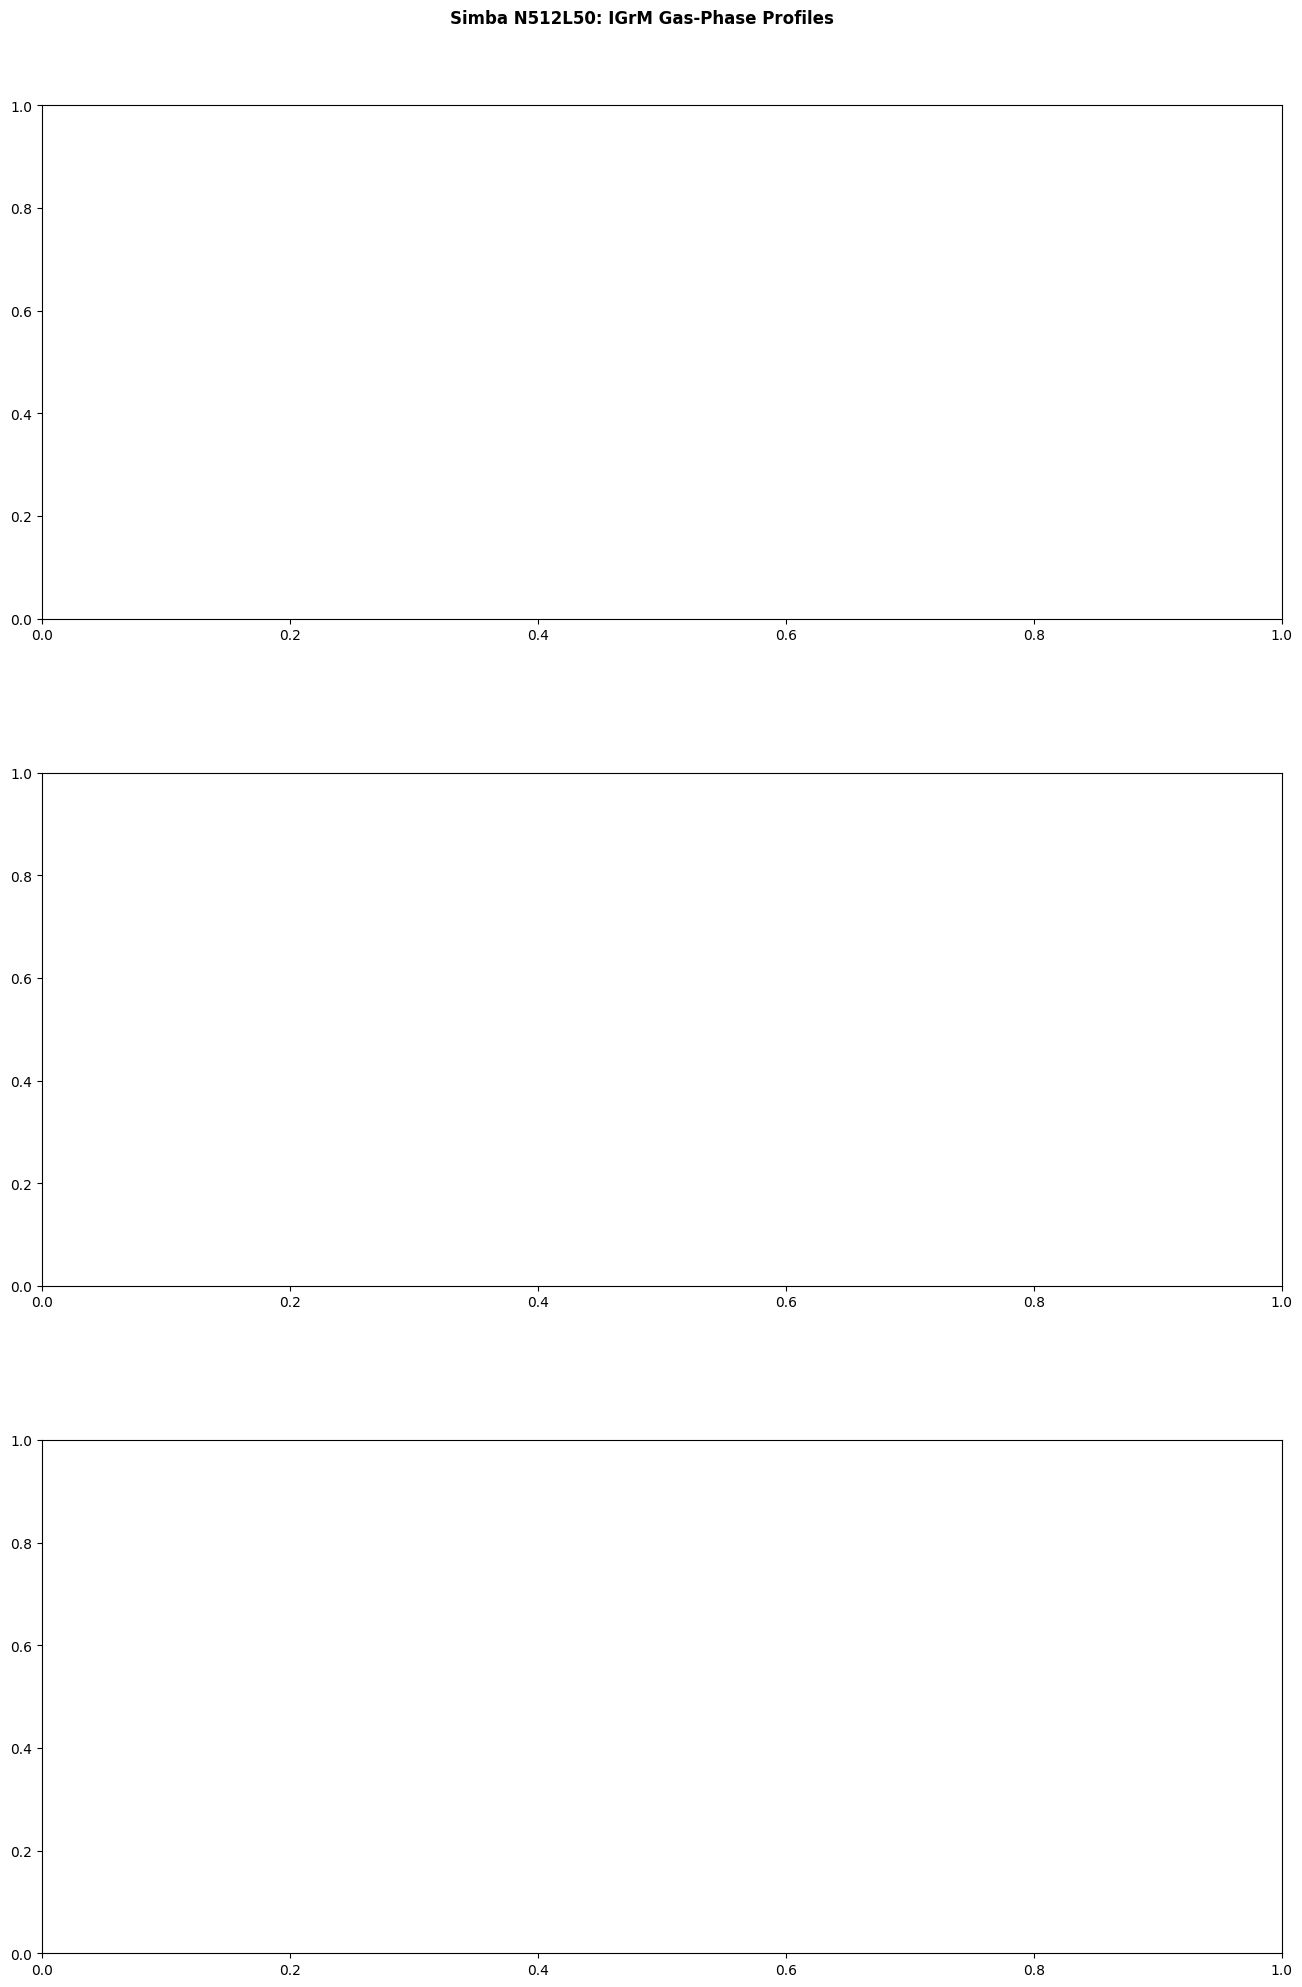

In [39]:
prop_ = 'n'
prop_name_ = r'$N_{res}$'

r_bin_idxs_ = [0,1,2]
# r_bin_idxs_ = [13]


for code_, info_ in profiles_info.items():

    bins_ = info_['profiles']['bins']


    fig, ax = plt.subplots(nrows=len(bins_), ncols=1, sharex=False, sharey='row',
                           figsize=(16,8*len(bins_)), constrained_layout=False, gridspec_kw={'wspace':0, 'hspace':0.3})

    fig.suptitle(r'%s N512L50: IGrM Gas-Phase Profiles' % code_, y=0.92, va='top', wrap=True, fontweight='bold')




    for mm in range(len(bins_)):
        bin_ = bins_[mm]
        print(bin_)
        axis_ = ax[mm]
    #     axis_ = plt
    
        for r_bin_idx_, color_ in zip(r_bin_idxs_, COLOR_LIST[3]):
            
            bin_prop_vals_ = []
            for halo_ in info_['profiles'][bin_]['all_id']:
                bin_prop_vals_.append(info_['profiles'][bin_][halo_]['y'][prop_][r_bin_idx_])
                
            bin_prop_vals_ = np.array(bin_prop_vals_)
            
            bin_label_ = '%s < %s < %s' % (round(info_['XAXIS_BINS'][r_bin_idx_], 3), 
                                           profiles_xaxis_label, 
                                           round(info_['XAXIS_BINS'][r_bin_idx_+1], 3))
            axis_.hist(bin_prop_vals_, color=color_, label=bin_label_, histtype='step', log=False, lw=3)#, bins=5)
            
            

        axis_.set_xlabel(r'%s$\,$[%s]' % (prop_name_,
                                    info_['profiles'][bin_][info_['profiles'][bin_]['id'][0]]['y'][prop_].units))
        axis_.set_ylabel('Count')
        axis_.set_title(r'$%.2e < M_{500}/M_{\odot} \leq %.2e$' % 
                  (profiles_info[code_]['profiles']['bin_edges'][bin_], 
                   profiles_info[code_]['profiles']['bin_edges'][bin_+1]), 
                         x=0.02, y=0.05, fontweight='bold', fontsize='small', ha='left', wrap=True)

#         axis_.set_xscale('log')
#         axis_.set_yscale('log')
        axis_.minorticks_on()
        axis_.grid()
        axis_.legend()

    plt.show()
    
    print()
    print()
    print()

## Slicing through radial bins across all individual profiles and plotting as a function of another property (eg. M500) to look at correlation

In [ ]:
prop_ = 'n'
prop_name_ = r'$N_{res}$'

halo_prop_ = 'M'
halo_prop_type_ = '500'

r_bin_idxs_ = [0,1,2]
# r_bin_idxs_ = [13]


for code_, info_ in profiles_info.items():
    bins_ = info_['profiles']['bins']

    fig, ax = plt.subplots(nrows=len(bins_), ncols=1, sharex=False, sharey='row',
                           figsize=(16,8*len(bins_)), constrained_layout=False, gridspec_kw={'wspace':0, 'hspace':0.3})

    fig.suptitle(r'%s N512L50: IGrM Gas-Phase Profiles' % code_, y=0.92, va='top', wrap=True, fontweight='bold')




    for mm in range(len(bins_)):
        bin_ = bins_[mm]
        print(bin_)
        axis_ = ax[mm]
    #     axis_ = plt
    
        for r_bin_idx_, color_ in zip(r_bin_idxs_, COLOR_LIST[3]):
            
            bin_prop_vals_ = []
            halo_prop_vals_ = []
            for halo_idx_ in range(len(info_['profiles'][bin_]['id'])):
                halo_ = info_['profiles'][bin_]['id'][halo_idx_]
                bin_prop_vals_.append(info_['profiles'][bin_][halo_]['y'][prop_][r_bin_idx_])
                halo_prop_vals_.append(info_['profiles'][bin_]['halo_info'][halo_prop_][halo_prop_type_][halo_idx_])
                
            bin_prop_vals_ = np.array(bin_prop_vals_)
            halo_prop_vals_ = np.array(halo_prop_vals_)
            
            bin_label_ = '%s < %s < %s' % (round(info_['XAXIS_BINS'][r_bin_idx_], 3), 
                                           profiles_xaxis_label, 
                                           round(info_['XAXIS_BINS'][r_bin_idx_+1], 3))
            axis_.scatter(halo_prop_vals_, bin_prop_vals_, color=color_, label=bin_label_)
            
            

        axis_.set_xlabel('%s%s' % (halo_prop_, halo_prop_type_))
        axis_.set_ylabel(r'%s$\,$[%s]' % (prop_name_,
                                    info_['profiles'][bin_][info_['profiles'][bin_]['id'][0]]['y'][prop_].units))
        axis_.set_title(r'$%.2e < M_{500}/M_{\odot} \leq %.2e$' % 
                  (profiles_info[code_]['profiles']['bin_edges'][bin_], 
                   profiles_info[code_]['profiles']['bin_edges'][bin_+1]), 
                         x=0.02, y=0.05, fontweight='bold', fontsize='small', ha='left', wrap=True)

#         axis_.set_xscale('log')
#         axis_.set_yscale('log')
        axis_.minorticks_on()
        axis_.grid()
        axis_.legend()

    plt.show()
    
    print()
    print()
    print()

In [ ]:
## Check the correlation of CC/NCC classification with binning property

bin_prop_ = ['M', '500']

classifications_ = ['Tspec_CC_frac', 'Tspec_NCC_frac']
# classifications_ = ['all']
classifications_colors_ = ['blue', 'red']
# classifications_colors_ = ['black']
classifications_vals_ = [-1, 1]

# fig, ax = plt.subplots(nrows=len(profiles_info.keys()), ncols=1, sharex='col', sharey=False,
#                        figsize=(16,8*len(profiles_info.keys())), constrained_layout=False, gridspec_kw={'wspace':0, 'hspace':0})
fig, ax = plt.subplots(nrows=len(profiles_info.keys())+1, ncols=1, sharex='col', sharey=False,
                       figsize=(16,8*len(profiles_info.keys())+1), constrained_layout=False, gridspec_kw={'wspace':0, 'hspace':0})

# fig.suptitle(r'%s N512L50 IGrM' % code_, y=1, va='top', wrap=True, fontweight='bold')
# fig.suptitle(r'%s N512L50 IGrM' % code_, y=1.0, va='top', wrap=True, fontweight='bold')

axis_count = 0

for code_, info_ in profiles_info.items():
    axis_ = ax[axis_count]
    
    axis_.set_title(code_, x=0.05, y=0.5, fontweight='bold', fontsize='large', ha='left', wrap=True, zorder=1000)
    
    bins_ = info_['profiles']['bins']

    bin_prop_label_ = r'%s' % info_['BIN_NAME']

    
    for classification_, classification_color_, classification_val_ in zip(classifications_, classifications_colors_, classifications_vals_):

        for mm in range(len(bins_)):
            bin_ = bins_[mm]
            print(bin_)
#             axis_ = ax#[mm]
        #     axis_ = plt


            for halo in info_['profiles'][bin_][classification_+'_id']:

                halo_idx = list(info_['profiles'][bin_]['all_id']).index(halo)
                bin_val_ = np.log10(info_['profiles'][bin_]['halo_info'][bin_prop_[0]][bin_prop_[1]][halo_idx])
                
                axis_.scatter(bin_val_, classification_val_, s=100, color=classification_color_, label=classification_)
                
                
    axis_.set_xlabel('log(%s)' % bin_prop_label_)

#     axis_.set_title(bin_label_, x=0.02, y=0.05, fontweight='bold', fontsize='small', ha='left', wrap=True, zorder=1000)

#     ax.set_xscale('log')
    axis_.minorticks_on()
    axis_.grid()
    axis_.tick_params(axis='both', direction='in', which='both', zorder=0, length=8, width=3)
    
    
    axis_count += 1
    
    

# Define a dictionary to store legend information
legend_info = {}

# Get the legend information from all subplots
for ax_ in ax.flatten():
    lines, labels = ax_.get_legend_handles_labels()
    for line, label in zip(lines, labels):
        legend_info[label] = line  # Store line information with label

# # Remove duplicate labels
# unique_legend_labels = list(set(legend_labels))
# print(unique_legend_labels)

# Create a new subplot above the existing ones for the legend
plt.subplots_adjust(top=0.85)  # Adjust the top margin to make space for the legend
legend_ax = fig.add_subplot(111, frameon=False)
legend_ax.get_xaxis().set_visible(False)
legend_ax.get_yaxis().set_visible(False)

# Add the legend with the unique labels, colors, and formats
handles = [legend_info[label] for label in legend_info.keys()]
labels = legend_info.keys()
legend_ax.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.1))
#     legend_ax.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.2))


# Save and show plot
#     plt.savefig(os.path.join('plots','%s_%s_profiles.png' % (code_, props_[0])), format='png', bbox_inches='tight', facecolor='white')
plt.show()

###### 